# Classification: SwinBase

This notebook fine-tunes a pretrained **SwinBase** on brain MRI images and benchmarks it.
Every notebook in this folder follows the same pipeline; only the model architecture differs.

**Pipeline**
1. Configuration, notebook settings and shared helpers
2. Data collection, exploration and splitting (with visualisations)
3. Model initialisation and model profile (parameters, size, FLOPs)
4. Training with per-epoch tracking (loss, accuracy, AUC, learning rate, timing, GPU memory)
5. Testing on the unseen test set
6. Detailed evaluation: metrics, confusion matrices, ROC/PR curves, calibration, per-class metrics
7. Explainability with Grad-CAM
8. Inference benchmark and consolidated benchmark summary
9. Packaging of all outputs into a single downloadable zip

The data, split, training and testing cells are the original ones. The added cells only observe the run
(they save and restore random number generator state where they use randomness), so the training setup is unchanged.

## Imports

Libraries used for data handling, modelling, metrics and logging.

In [1]:
# ================= IMPORTS =================
import os
import random
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from datetime import datetime

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import swin_transformer
from torchvision.models.swin_transformer import Swin_B_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

from torch.utils.tensorboard import SummaryWriter

## Configuration

Hyperparameters, data loading settings, device selection and seeding.

In [2]:
# ================= CONFIG =================
SEED = 42

BATCH_SIZE = 64
EPOCHS = 10
LR = 3e-4
IMG_SIZE = 224

NUM_WORKERS = 4
PIN_MEMORY = True
PERSISTENT_WORKERS = True
PREFETCH_FACTOR = 4

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

CUDA available: True
GPU count: 2


## Notebook settings

The settings that identify this notebook: model name, task, class names and the layer used for Grad-CAM.
Grad-CAM target layer: `features[-1][-1].norm1` (torchvision Swin, final block, channels-last).

In [3]:
# Notebook settings
MODEL_NAME = "SwinBase"
TASK = "classification"
CLASS_NAMES = ["Glioma", "Meningioma", "Pituitary"]
RUN_NAME = "classification-swinbase"


def get_gradcam_target_layer(net):
    """Return the layer used for Grad-CAM on the unwrapped (non-DataParallel) model."""
    return net.features[-1][-1].norm1


print(f"Run: {RUN_NAME} | Model: {MODEL_NAME} | Classes: {CLASS_NAMES}")

Run: classification-swinbase | Model: SwinBase | Classes: ['Glioma', 'Meningioma', 'Pituitary']


## Output folders and shared helpers

Creates the output folder structure under `/kaggle/working/outputs/` and defines helpers for saving plots,
tables and JSON, unwrapping `DataParallel`, un-normalising images and preserving random number generator state.

In [4]:
# Output folders and shared helpers
import copy
import io
import json
import math
import platform
import random
import time
import traceback
import zipfile
from contextlib import contextmanager
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import FileLink, display
from PIL import Image
from sklearn import metrics as skm
from tqdm.auto import tqdm

WORKING_DIR = Path("/kaggle/working")
OUTPUT_DIR = WORKING_DIR / "outputs" / RUN_NAME
PLOTS_DIR = OUTPUT_DIR / "plots"
METRICS_DIR = OUTPUT_DIR / "metrics"
for directory in (PLOTS_DIR, METRICS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

NUM_CLASSES = len(CLASS_NAMES)
IS_BINARY = NUM_CLASSES == 2
CLASS_COLOURS = plt.get_cmap("tab10").colors[:NUM_CLASSES]
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])

plt.rcParams.update(
    {"figure.dpi": 100, "savefig.dpi": 150, "axes.grid": True, "grid.alpha": 0.3}
)


def _to_builtin(value):
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    return str(value)


def save_fig(fig, name):
    path = PLOTS_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved plot: {path}")


def save_json(data, name):
    path = METRICS_DIR / f"{name}.json"
    with open(path, "w") as f:
        json.dump(data, f, indent=2, default=_to_builtin)
    print(f"Saved JSON: {path}")


def save_table(frame, name, index=False):
    path = METRICS_DIR / f"{name}.csv"
    frame.to_csv(path, index=index)
    print(f"Saved table: {path}")


def save_text(text, name):
    path = METRICS_DIR / f"{name}.txt"
    path.write_text(text)
    print(f"Saved text: {path}")


def unwrap_model(net):
    return net.module if isinstance(net, nn.DataParallel) else net


def denormalise(tensor):
    image = tensor.detach().cpu().permute(1, 2, 0).numpy()
    return np.clip(image * IMAGENET_STD + IMAGENET_MEAN, 0, 1)


def sync_cuda():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


@contextmanager
def preserved_rng_state():
    """Restore Python, NumPy and PyTorch RNG state so added cells do not alter training randomness."""
    python_state = random.getstate()
    numpy_state = np.random.get_state()
    torch_state = torch.get_rng_state()
    cuda_states = torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
    try:
        yield
    finally:
        random.setstate(python_state)
        np.random.set_state(numpy_state)
        torch.set_rng_state(torch_state)
        if cuda_states is not None:
            torch.cuda.set_rng_state_all(cuda_states)


print("Outputs will be written to:", OUTPUT_DIR)

Outputs will be written to: /kaggle/working/outputs/classification-swinbase


## Data paths

Kaggle dataset folders for each tumour class.

In [5]:
# ================= DATA PATHS =================
GLIOMA_PATHS = [
    "/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/glioma_tumor",
    "/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Training/glioma_tumor",
    "/kaggle/input/datasets/moundir8/jun-cheng-brain-tumor-mri-dataset-jpg/brain tumor mri dataset/2_glioma",
]

MENINGIOMA_PATHS = [
    "/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/meningioma_tumor",
    "/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Training/meningioma_tumor",
    "/kaggle/input/datasets/moundir8/jun-cheng-brain-tumor-mri-dataset-jpg/brain tumor mri dataset/1_meningioma",
]

PITUITARY_PATHS = [
    "/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/pituitary_tumor",
    "/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Training/pituitary_tumor",
    "/kaggle/input/datasets/moundir8/jun-cheng-brain-tumor-mri-dataset-jpg/brain tumor mri dataset/3_pituitary_tumor",
]

VALID_EXTENSIONS = (".jpg",)

## Data collection

Walks the dataset folders and builds a dataframe of image paths and labels.

In [6]:
# ================= DATA COLLECTION =================
def collect(paths, label):
    items = []
    for path in paths:
        for root, _, files in os.walk(path):
            for f in files:
                if f.lower().endswith(VALID_EXTENSIONS):
                    items.append((os.path.join(root, f), label))
    return items


# Combine datasets
data = (
    collect(GLIOMA_PATHS, 0)
    + collect(MENINGIOMA_PATHS, 1)
    + collect(PITUITARY_PATHS, 2)
)

df = pd.DataFrame(data, columns=["path", "label"])
print("Total Images before deduplication:", len(df))
print("Class Distribution before deduplication:")
print(df["label"].value_counts())

Total Images before deduplication: 5828
Class Distribution before deduplication:
label
0    2352
2    1831
1    1645
Name: count, dtype: int64


## Dataset overview

Class distribution and sample images for every class in the collected dataset.
A copy of the collected dataframe (`df_raw`) is kept for later comparisons.

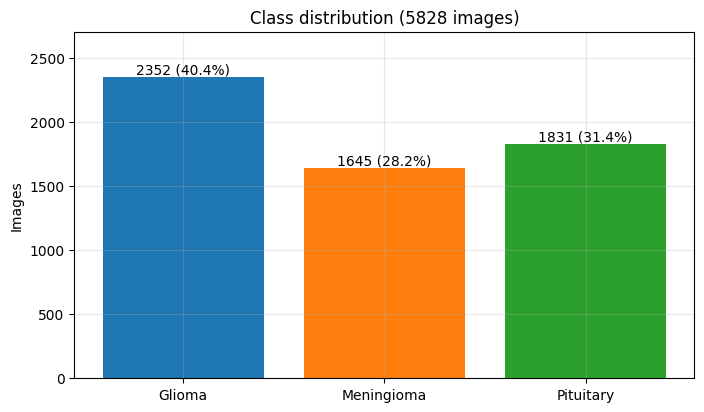

Saved plot: /kaggle/working/outputs/classification-swinbase/plots/01_class_distribution.png


Sample images:   0%|          | 0/3 [00:00<?, ?it/s]

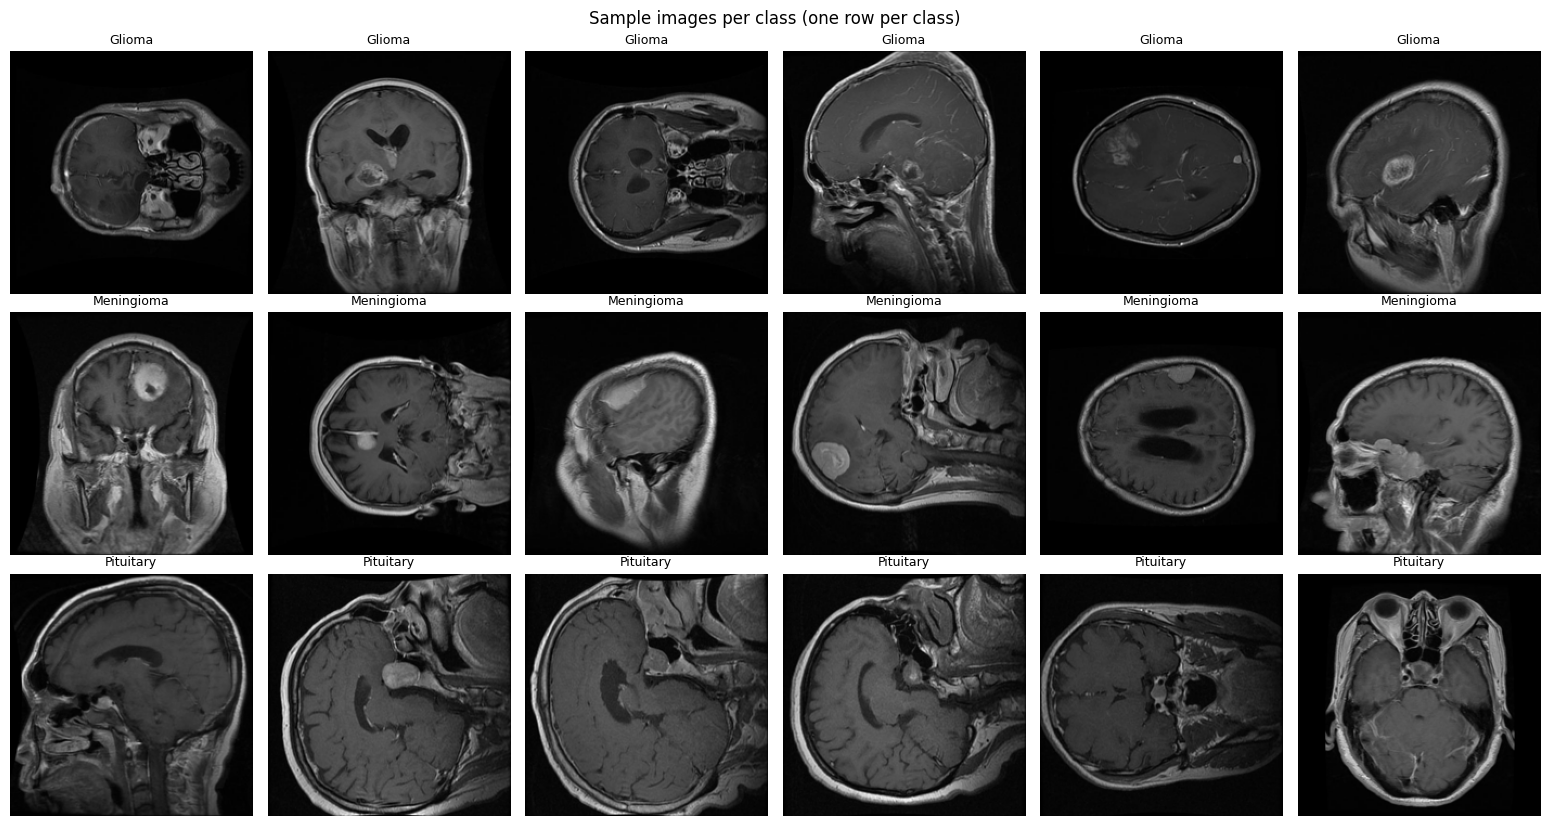

Saved plot: /kaggle/working/outputs/classification-swinbase/plots/02_sample_images.png


,images
label,
Glioma,2352
Meningioma,1645
Pituitary,1831


In [7]:
# Dataset overview: class distribution and sample images
with preserved_rng_state():
    df_raw = df.copy()
    raw_counts = (
        df_raw["label"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)
    )

    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(CLASS_NAMES, raw_counts.values, color=CLASS_COLOURS)
    ax.bar_label(
        bars, labels=[f"{c} ({c / raw_counts.sum():.1%})" for c in raw_counts.values]
    )
    ax.set_title(f"Class distribution ({raw_counts.sum()} images)")
    ax.set_ylabel("Images")
    ax.margins(y=0.15)
    save_fig(fig, "01_class_distribution")

    SAMPLES_PER_CLASS = 6
    fig, axes = plt.subplots(
        NUM_CLASSES,
        SAMPLES_PER_CLASS,
        figsize=(2.6 * SAMPLES_PER_CLASS, 2.8 * NUM_CLASSES),
        squeeze=False,
    )
    for class_idx, class_name in enumerate(tqdm(CLASS_NAMES, desc="Sample images")):
        class_rows = df_raw[df_raw["label"] == class_idx]
        sample_rows = class_rows.sample(
            min(SAMPLES_PER_CLASS, len(class_rows)), random_state=SEED
        )
        for col in range(SAMPLES_PER_CLASS):
            ax = axes[class_idx, col]
            ax.axis("off")
            if col < len(sample_rows):
                with Image.open(sample_rows.iloc[col]["path"]) as img:
                    ax.imshow(img.convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
                ax.set_title(class_name, fontsize=9)
    fig.suptitle("Sample images per class (one row per class)")
    fig.tight_layout()
    save_fig(fig, "02_sample_images")

display(raw_counts.rename(index=dict(enumerate(CLASS_NAMES))).to_frame("images"))

## Image properties

Original image dimensions and grayscale intensity distributions per class, with summary statistics saved to disk.

Reading image sizes:   0%|          | 0/5828 [00:00<?, ?it/s]

Intensities: Glioma:   0%|          | 0/100 [00:00<?, ?it/s]

Intensities: Meningioma:   0%|          | 0/100 [00:00<?, ?it/s]

Intensities: Pituitary:   0%|          | 0/100 [00:00<?, ?it/s]

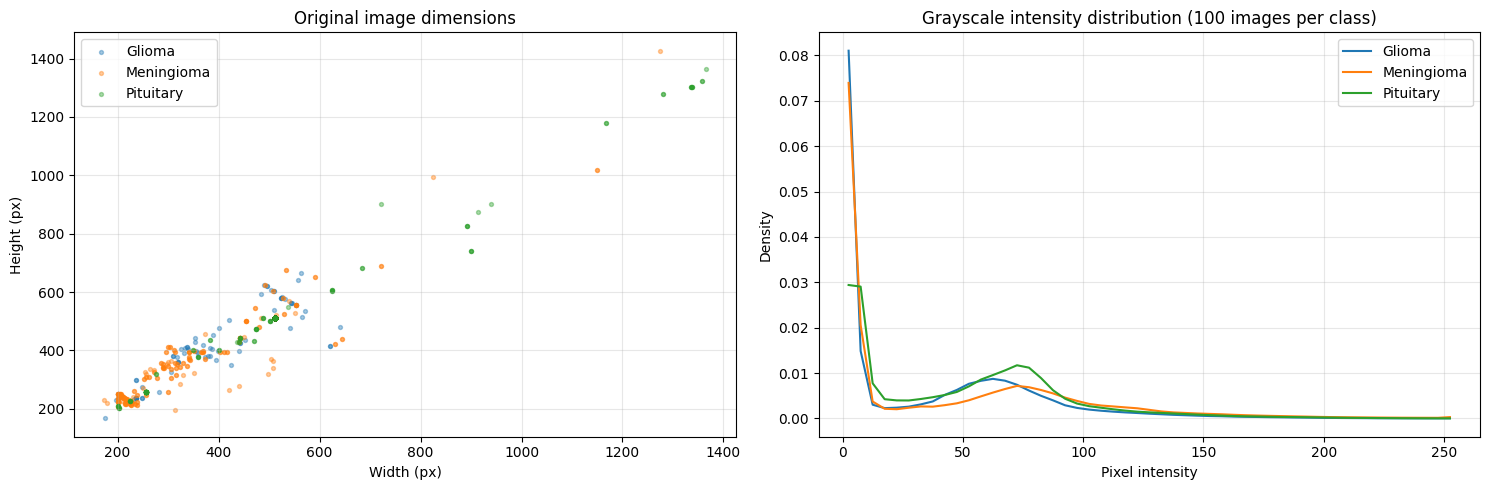

Saved plot: /kaggle/working/outputs/classification-swinbase/plots/03_image_properties.png
Saved table: /kaggle/working/outputs/classification-swinbase/metrics/image_dimension_stats.csv


width                                                             \
             count        mean        std    min    25%    50%    75%     max   
class_name                                                                      
Glioma      2352.0  507.567602  33.027921  175.0  512.0  512.0  512.0   640.0   
Meningioma  1645.0  483.133131  90.420556  174.0  512.0  512.0  512.0  1275.0   
Pituitary   1831.0  512.497542  84.387726  201.0  512.0  512.0  512.0  1365.0   

            height                                                             
             count        mean        std    min    25%    50%    75%     max  
class_name                                                                     
Glioma      2352.0  508.445578  30.610178  167.0  512.0  512.0  512.0   665.0  
Meningioma  1645.0  485.938602  85.110429  195.0  512.0  512.0  512.0  1427.0  
Pituitary   1831.0  512.187329  81.304382  202.0  512.0  512.0  512.0  1365.0

In [8]:
# Image properties: dimensions and intensity distributions
with preserved_rng_state():
    image_sizes = []
    for path in tqdm(df_raw["path"], desc="Reading image sizes"):
        with Image.open(path) as img:
            image_sizes.append(img.size)
    df_raw["width"] = [w for w, _ in image_sizes]
    df_raw["height"] = [h for _, h in image_sizes]

    INTENSITY_SAMPLES_PER_CLASS = 100
    intensity_bins = np.linspace(0, 255, 52)
    intensity_hists = {}
    for class_idx, class_name in enumerate(CLASS_NAMES):
        class_rows = df_raw[df_raw["label"] == class_idx]
        sample_rows = class_rows.sample(
            min(INTENSITY_SAMPLES_PER_CLASS, len(class_rows)), random_state=SEED
        )
        pixels = []
        for path in tqdm(sample_rows["path"], desc=f"Intensities: {class_name}"):
            with Image.open(path) as img:
                pixels.append(
                    np.asarray(img.convert("L").resize((IMG_SIZE, IMG_SIZE))).ravel()
                )
        intensity_hists[class_name], _ = np.histogram(
            np.concatenate(pixels), bins=intensity_bins, density=True
        )

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for class_idx, class_name in enumerate(CLASS_NAMES):
        class_rows = df_raw[df_raw["label"] == class_idx]
        axes[0].scatter(
            class_rows["width"],
            class_rows["height"],
            s=8,
            alpha=0.4,
            color=CLASS_COLOURS[class_idx],
            label=class_name,
        )
        axes[1].plot(
            (intensity_bins[:-1] + intensity_bins[1:]) / 2,
            intensity_hists[class_name],
            color=CLASS_COLOURS[class_idx],
            label=class_name,
        )
    axes[0].set_title("Original image dimensions")
    axes[0].set_xlabel("Width (px)")
    axes[0].set_ylabel("Height (px)")
    axes[0].legend()
    axes[1].set_title(
        f"Grayscale intensity distribution ({INTENSITY_SAMPLES_PER_CLASS} images per class)"
    )
    axes[1].set_xlabel("Pixel intensity")
    axes[1].set_ylabel("Density")
    axes[1].legend()
    fig.tight_layout()
    save_fig(fig, "03_image_properties")

image_stats = (
    df_raw.assign(class_name=df_raw["label"].map(dict(enumerate(CLASS_NAMES))))
    .groupby("class_name")[["width", "height"]]
    .describe()
)
save_table(image_stats, "image_dimension_stats", index=True)
display(image_stats)

## Deduplication

Removes near-duplicate images with perceptual hashing (pHash) and a Hamming distance tolerance.

In [9]:
# ================= DEDUPLICATE IMAGES (Perceptual Hashing) =================
import imagehash


def phash_image(path):
    try:
        with Image.open(path) as img:
            img = img.convert("RGB")
            return imagehash.phash(img)
    except Exception as e:
        print(f"Error reading {path}: {e}")
        return None


tqdm.pandas(desc="Hashing images (pHash)")
df["hash"] = df["path"].progress_apply(phash_image)

# Set Hamming distance tolerance
HAMMING_TOLERANCE = 5  # adjust tolerance: 0 = exact, higher = more lenient

# Deduplicate with tolerance
unique_indices = []
seen_hashes = []

for idx, h in enumerate(df["hash"]):
    if h is None:
        continue
    if all(h - existing > HAMMING_TOLERANCE for existing in seen_hashes):
        seen_hashes.append(h)
        unique_indices.append(idx)

df = df.loc[unique_indices].reset_index(drop=True)
df = df.drop(columns="hash")

print("Total Images after deduplication:", len(df))
print("Class Distribution after deduplication:")
print(df["label"].value_counts())

Hashing images (pHash):   0%|          | 0/5828 [00:00<?, ?it/s]

Total Images after deduplication: 4705
Class Distribution after deduplication:
label
0    2000
2    1401
1    1304
Name: count, dtype: int64


## Deduplication: before vs after

Class counts before (top) and after (bottom) perceptual-hash deduplication, stacked in one figure on shared axes.

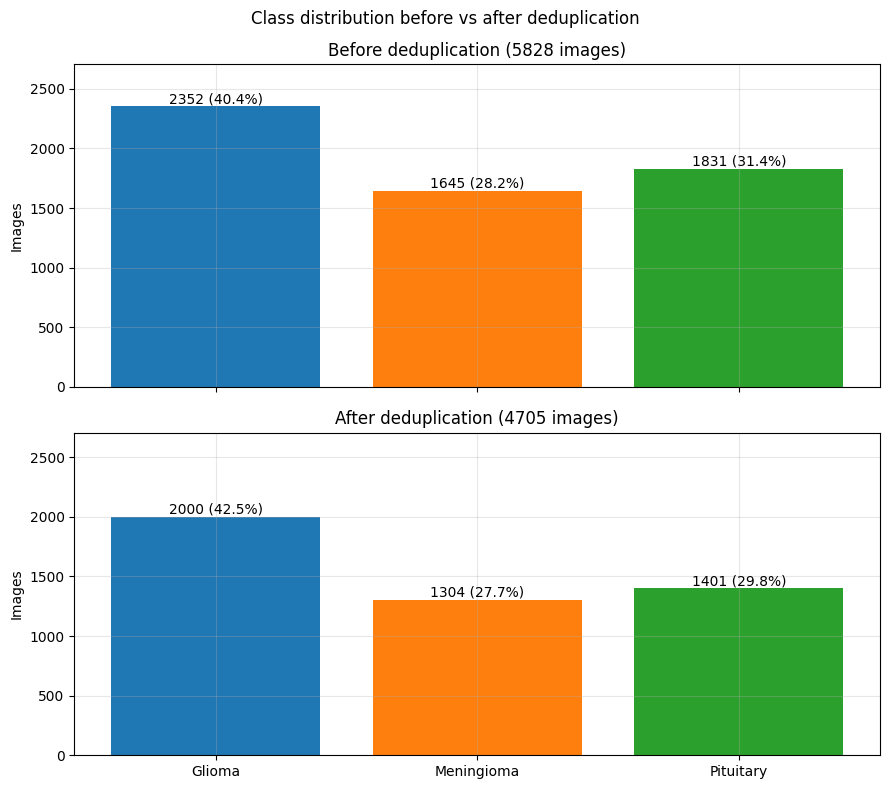

Saved plot: /kaggle/working/outputs/classification-swinbase/plots/04_deduplication_before_after.png
Saved table: /kaggle/working/outputs/classification-swinbase/metrics/deduplication_summary.csv


,class,before,after,removed,removed_pct
0,Glioma,2352,2000,352,14.97
1,Meningioma,1645,1304,341,20.73
2,Pituitary,1831,1401,430,23.48


In [10]:
# Deduplication: before (top) vs after (bottom)
with preserved_rng_state():
    counts_before = (
        df_raw["label"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)
    )
    counts_after = df["label"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)

    fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True, sharey=True)
    for ax, counts, stage in zip(
        axes,
        [counts_before, counts_after],
        ["Before deduplication", "After deduplication"],
    ):
        bars = ax.bar(CLASS_NAMES, counts.values, color=CLASS_COLOURS)
        ax.bar_label(
            bars, labels=[f"{c} ({c / counts.sum():.1%})" for c in counts.values]
        )
        ax.set_title(f"{stage} ({counts.sum()} images)")
        ax.set_ylabel("Images")
        ax.margins(y=0.15)
    fig.suptitle("Class distribution before vs after deduplication")
    fig.tight_layout()
    save_fig(fig, "04_deduplication_before_after")

dedup_summary = pd.DataFrame(
    {
        "class": CLASS_NAMES,
        "before": counts_before.values,
        "after": counts_after.values,
    }
)
dedup_summary["removed"] = dedup_summary["before"] - dedup_summary["after"]
dedup_summary["removed_pct"] = (
    100 * dedup_summary["removed"] / dedup_summary["before"]
).round(2)
save_table(dedup_summary, "deduplication_summary")
display(dedup_summary)

## Train, validation and test split

Stratified 70 / 15 / 15 split.

In [11]:
# ================= SPLIT DATA =================
train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df["label"], random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df["label"], random_state=SEED
)

print("Train:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))

Train: 3293
Val: 706
Test: 706


## Split distribution

Class counts and proportions in the train, validation and test splits.

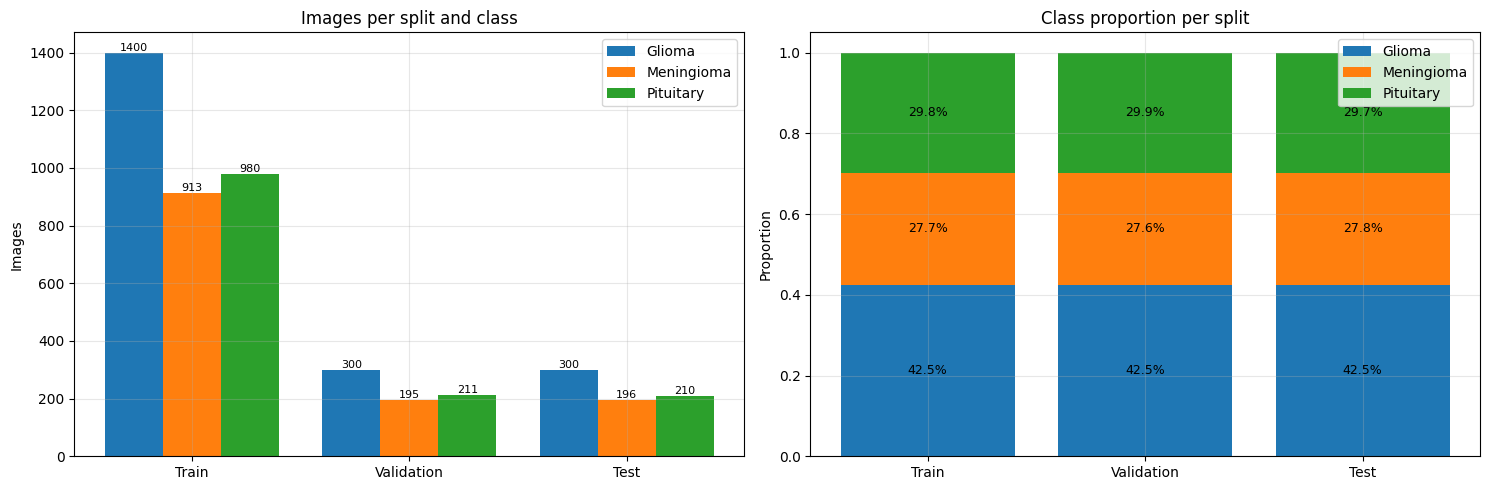

Saved plot: /kaggle/working/outputs/classification-swinbase/plots/05_split_distribution.png
Saved table: /kaggle/working/outputs/classification-swinbase/metrics/split_distribution.csv


,Train,Validation,Test
Glioma,1400,300,300
Meningioma,913,195,196
Pituitary,980,211,210
Total,3293,706,706


In [12]:
# Split distribution per class
with preserved_rng_state():
    split_frames = {"Train": train_df, "Validation": val_df, "Test": test_df}
    split_counts = pd.DataFrame(
        {
            split: frame["label"]
            .value_counts()
            .reindex(range(NUM_CLASSES), fill_value=0)
            .values
            for split, frame in split_frames.items()
        },
        index=CLASS_NAMES,
    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    x = np.arange(len(split_frames))
    width = 0.8 / NUM_CLASSES
    for class_idx, class_name in enumerate(CLASS_NAMES):
        bars = axes[0].bar(
            x + (class_idx - (NUM_CLASSES - 1) / 2) * width,
            split_counts.loc[class_name].values,
            width,
            color=CLASS_COLOURS[class_idx],
            label=class_name,
        )
        axes[0].bar_label(bars, fontsize=8)
    axes[0].set_xticks(x, list(split_frames))
    axes[0].set_title("Images per split and class")
    axes[0].set_ylabel("Images")
    axes[0].legend()

    split_share = split_counts / split_counts.sum(axis=0)
    bottom = np.zeros(len(split_frames))
    for class_idx, class_name in enumerate(CLASS_NAMES):
        values = split_share.loc[class_name].values
        axes[1].bar(
            list(split_frames),
            values,
            bottom=bottom,
            color=CLASS_COLOURS[class_idx],
            label=class_name,
        )
        for i, (b, v) in enumerate(zip(bottom, values)):
            axes[1].text(i, b + v / 2, f"{v:.1%}", ha="center", va="center", fontsize=9)
        bottom += values
    axes[1].set_title("Class proportion per split")
    axes[1].set_ylabel("Proportion")
    axes[1].legend(loc="upper right")
    fig.tight_layout()
    save_fig(fig, "05_split_distribution")

split_table = split_counts.copy()
split_table.loc["Total"] = split_table.sum()
save_table(split_table, "split_distribution", index=True)
display(split_table)

## Dataset class

PyTorch dataset that loads an image and its label.

In [13]:
# ================= DATASET CLASS =================
class BrainDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "path"]
        label = self.df.loc[idx, "label"]

        try:
            img = Image.open(img_path).convert("RGB")
        except Exception as e:
            raise RuntimeError(f"Failed loading image: {img_path}") from e

        if self.transform:
            img = self.transform(img)

        return img, torch.tensor(label, dtype=torch.long)

## Transforms

Training augmentation and evaluation transforms.

In [14]:
# ================= TRANSFORMS =================
train_tfms = transforms.Compose(
    [
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.ColorJitter(0.2, 0.2),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)

val_tfms = transforms.Compose(
    [
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)

## Data loaders

Train, validation and test data loaders.

In [15]:
# ================= DATALOADERS =================
train_loader = DataLoader(
    BrainDataset(train_df, train_tfms),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT_WORKERS,
    prefetch_factor=PREFETCH_FACTOR,
    drop_last=True,
)

val_loader = DataLoader(
    BrainDataset(val_df, val_tfms),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT_WORKERS,
    prefetch_factor=PREFETCH_FACTOR,
    drop_last=False,
)

test_loader = DataLoader(
    BrainDataset(test_df, val_tfms),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT_WORKERS,
    prefetch_factor=PREFETCH_FACTOR,
    drop_last=False,
)

## Augmentation: original vs augmented

The same images before augmentation (top row, evaluation transform) and after the training augmentation
(bottom row), stacked in one figure.

Augmenting samples:   0%|          | 0/6 [00:00<?, ?it/s]

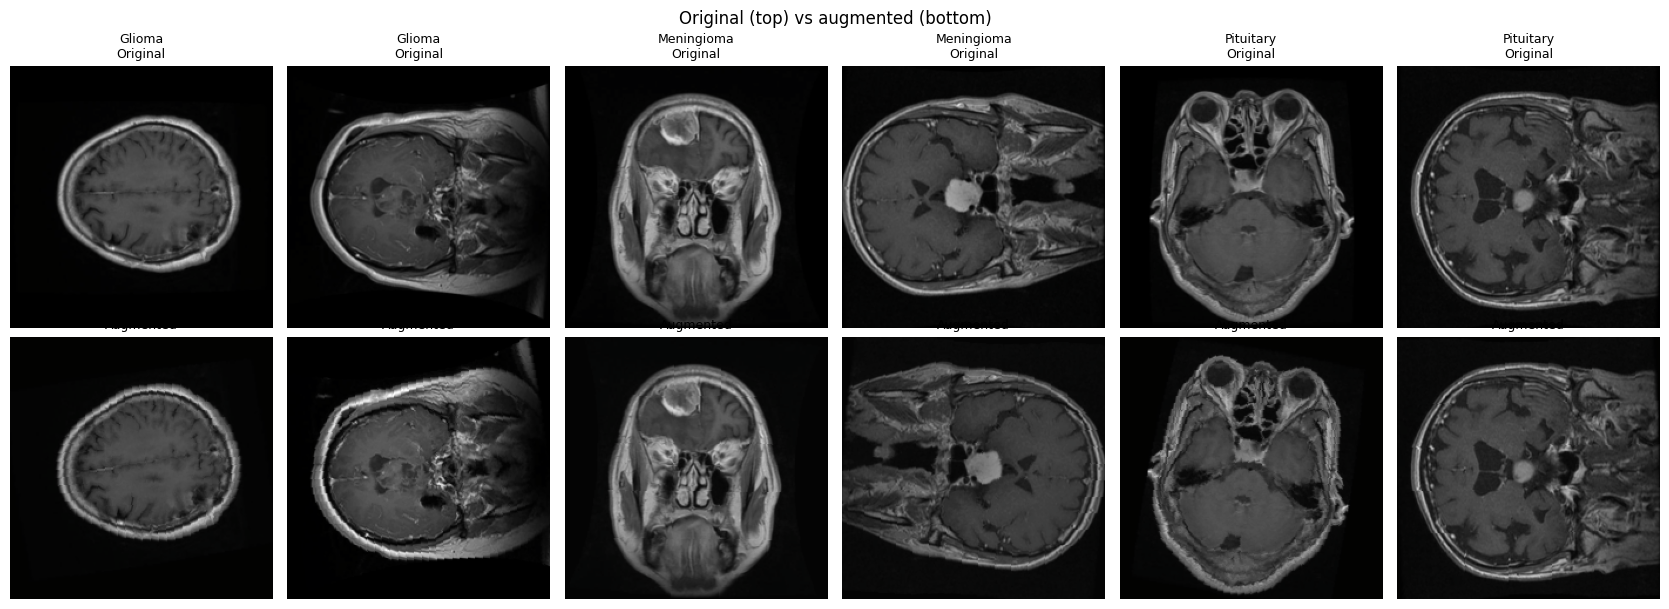

Saved plot: /kaggle/working/outputs/classification-swinbase/plots/06_augmentation_before_after.png


In [16]:
# Augmentation: original (top) vs augmented (bottom)
with preserved_rng_state():
    AUGMENTATION_COLUMNS = 6
    per_class = max(1, AUGMENTATION_COLUMNS // NUM_CLASSES)
    augmentation_rows = pd.concat(
        [
            train_df[train_df["label"] == k].sample(
                min(per_class, int((train_df["label"] == k).sum())), random_state=SEED
            )
            for k in range(NUM_CLASSES)
        ]
    )
    n_cols = len(augmentation_rows)

    fig, axes = plt.subplots(2, n_cols, figsize=(2.8 * n_cols, 6.2), squeeze=False)
    for col, (_, row) in enumerate(
        tqdm(augmentation_rows.iterrows(), total=n_cols, desc="Augmenting samples")
    ):
        with Image.open(row["path"]) as img:
            img = img.convert("RGB")
            original = denormalise(val_tfms(img))
            augmented = denormalise(train_tfms(img))
        class_name = CLASS_NAMES[int(row["label"])]
        axes[0, col].imshow(original)
        axes[0, col].set_title(f"{class_name}\nOriginal", fontsize=9)
        axes[1, col].imshow(augmented)
        axes[1, col].set_title("Augmented", fontsize=9)
        axes[0, col].axis("off")
        axes[1, col].axis("off")
    fig.suptitle("Original (top) vs augmented (bottom)")
    fig.tight_layout()
    save_fig(fig, "06_augmentation_before_after")

## Model initialisation

Pretrained **SwinBase** with a new classification head, multi-GPU wrapping, loss, optimiser,
cosine learning rate schedule and mixed-precision scaler.

In [17]:
# ================= MODEL =================
from torchvision.models import swin_b, Swin_B_Weights

# Load pretrained Swin-Base model
model = swin_b(weights=Swin_B_Weights.DEFAULT)

# Replace classifier head for 3 classes
model.head = nn.Linear(
    model.head.in_features, 3
)  # 3 classes (glioma, meningioma, pituitary)

# Handle multi-GPU setup
if torch.cuda.device_count() > 1:
    print(f"Using {torch.cuda.device_count()} GPUs")
    model = nn.DataParallel(model)

# Move model to device
model = model.to(DEVICE)

# Loss function, optimizer, and scheduler
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

# Mixed precision training scaler
scaler = torch.amp.GradScaler("cuda")

print(f"Model loaded successfully on {DEVICE}")
print(f"Number of parameters: {sum(p.numel() for p in model.parameters()):,}")

Downloading: "https://download.pytorch.org/models/swin_b-68c6b09e.pth" to /root/.cache/torch/hub/checkpoints/swin_b-68c6b09e.pth


100%|██████████| 335M/335M [00:01<00:00, 210MB/s] 


Using 2 GPUs
Model loaded successfully on cuda
Number of parameters: 86,746,299


## Model profile

Parameter counts, serialised size and FLOPs for one input image, used for benchmarking across models.

In [18]:
# Model profile: parameters, size and FLOPs
from torch.utils.flop_counter import FlopCounterMode

with preserved_rng_state():
    base_model = unwrap_model(model)
    total_params = sum(p.numel() for p in base_model.parameters())
    trainable_params = sum(
        p.numel() for p in base_model.parameters() if p.requires_grad
    )
    buffer_count = sum(b.numel() for b in base_model.buffers())

    state_buffer = io.BytesIO()
    torch.save(base_model.state_dict(), state_buffer)
    serialised_size_mb = state_buffer.getbuffer().nbytes / 1024**2
    del state_buffer

    flops = None
    try:
        profile_model = copy.deepcopy(base_model).cpu().eval()
        with torch.no_grad(), FlopCounterMode(display=False) as flop_counter:
            profile_model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE))
        flops = flop_counter.get_total_flops()
        del profile_model
    except Exception as exc:
        print(f"FLOPs could not be computed: {exc}")

model_profile = {
    "architecture": type(base_model).__name__,
    "total_parameters": total_params,
    "trainable_parameters": trainable_params,
    "non_trainable_parameters": total_params - trainable_params,
    "total_parameters_millions": round(total_params / 1e6, 3),
    "buffer_elements": buffer_count,
    "parameter_memory_fp32_mb": round(total_params * 4 / 1024**2, 2),
    "serialised_state_dict_mb": round(serialised_size_mb, 2),
    "input_size": f"3x{IMG_SIZE}x{IMG_SIZE}",
    "flops_per_image": flops,
    "gflops_per_image": round(flops / 1e9, 3) if flops is not None else None,
    "data_parallel_gpus": (
        torch.cuda.device_count() if isinstance(model, nn.DataParallel) else 1
    ),
}
save_json(model_profile, "model_profile")
display(pd.Series(model_profile, name="value").to_frame())

Saved JSON: /kaggle/working/outputs/classification-swinbase/metrics/model_profile.json


,value
architecture,SwinTransformer
total_parameters,86746299
trainable_parameters,86746299
non_trainable_parameters,0
total_parameters_millions,86.746
buffer_elements,57624
parameter_memory_fp32_mb,330.91
serialised_state_dict_mb,331.47
input_size,3x224x224
flops_per_image,30859851776


## Train and evaluation epoch function

Runs one pass over a data loader and returns loss, accuracy and AUC.

In [19]:
# ================= EPOCH FUNCTION =================
def run_epoch(loader, training=True):
    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    loop = tqdm(
        loader, total=len(loader), desc="Train" if training else "Val/Test", leave=False
    )

    for images, labels in loop:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.amp.autocast(device_type="cuda", enabled=True):
            outputs = model(images)
            loss = criterion(outputs, labels)

        if training:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        total_loss += loss.item()
        probs = torch.softmax(outputs, dim=1).detach()
        all_preds.append(probs.cpu())
        all_labels.append(labels.detach().cpu())

        loop.set_postfix(loss=f"{loss.item():.4f}")

    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    acc = accuracy_score(all_labels, all_preds.argmax(axis=1))
    auc = roc_auc_score(np.eye(3)[all_labels], all_preds, multi_class="ovr")

    return total_loss / len(loader), acc, auc

## Training tracker

Wraps `run_epoch` so the unchanged training cell records per-epoch loss, accuracy, AUC, learning rate and
phase timings, and shows a real-time epoch progress bar. It also starts the training timer and resets GPU
peak-memory statistics.

In [20]:
# Training tracker: wraps run_epoch without changing the training cell
if not getattr(run_epoch, "_tracks_history", False):
    _untracked_run_epoch = run_epoch

history_rows = []
_pending_epoch = {}
_epoch_progress = None
TRAINING_START_TIME = None
TRAINING_END_TIME = None
TRAINING_STARTED_AT = None
test_phase_seconds = None


def run_epoch(loader, training=True):
    global _pending_epoch, _epoch_progress, TRAINING_START_TIME, TRAINING_END_TIME
    global TRAINING_STARTED_AT, test_phase_seconds

    if loader is train_loader:
        phase = "train"
    elif loader is val_loader:
        phase = "val"
    else:
        phase = "test"

    current_lr = optimizer.param_groups[0]["lr"]
    sync_cuda()
    start = time.perf_counter()
    loss, acc, auc_value = _untracked_run_epoch(loader, training)
    sync_cuda()
    elapsed = time.perf_counter() - start

    if phase == "train":
        if TRAINING_START_TIME is None:
            TRAINING_START_TIME = start
            TRAINING_STARTED_AT = datetime.now().isoformat(timespec="seconds")
        if _epoch_progress is None:
            _epoch_progress = tqdm(
                total=EPOCHS, desc=f"{MODEL_NAME} epochs", unit="epoch"
            )
        _pending_epoch = {
            "epoch": len(history_rows) + 1,
            "lr": current_lr,
            "train_loss": loss,
            "train_acc": acc,
            "train_auc": auc_value,
            "train_time_s": elapsed,
        }
    elif phase == "val" and _pending_epoch:
        _pending_epoch.update(
            {
                "val_loss": loss,
                "val_acc": acc,
                "val_auc": auc_value,
                "val_time_s": elapsed,
                "epoch_time_s": _pending_epoch["train_time_s"] + elapsed,
            }
        )
        history_rows.append(_pending_epoch)
        _pending_epoch = {}
        TRAINING_END_TIME = time.perf_counter()
        _epoch_progress.update(1)
        _epoch_progress.set_postfix(
            train_loss=f"{history_rows[-1]['train_loss']:.4f}",
            val_loss=f"{loss:.4f}",
            val_auc=f"{auc_value:.4f}",
        )
        if len(history_rows) >= EPOCHS:
            _epoch_progress.close()
    elif phase == "test":
        test_phase_seconds = elapsed

    return loss, acc, auc_value


run_epoch._tracks_history = True

if torch.cuda.is_available():
    for device_idx in range(torch.cuda.device_count()):
        torch.cuda.reset_peak_memory_stats(device_idx)

print("Training tracker ready.")

Training tracker ready.


## Training loop

Trains for the configured number of epochs, logs to TensorBoard and saves the checkpoint with the best validation AUC.

In [21]:
# ================= TRAINING =================
log_dir = f"/kaggle/working/runs/{datetime.now().strftime('%Y%m%d-%H%M%S')}"
writer = SummaryWriter(log_dir)

best_auc = 0.0

for epoch in range(EPOCHS):
    print(f"\n===== Epoch {epoch+1}/{EPOCHS} =====")

    train_loss, train_acc, train_auc = run_epoch(train_loader, True)
    val_loss, val_acc, val_auc = run_epoch(val_loader, False)

    scheduler.step()

    print(
        f"Train | Loss: {train_loss:.4f} | Acc: {train_acc:.4f} | AUC: {train_auc:.4f}"
    )
    print(f"Val   | Loss: {val_loss:.4f} | Acc: {val_acc:.4f} | AUC: {val_auc:.4f}")

    writer.add_scalar("Loss/Train", train_loss, epoch)
    writer.add_scalar("Loss/Val", val_loss, epoch)
    writer.add_scalar("AUC/Train", train_auc, epoch)
    writer.add_scalar("AUC/Val", val_auc, epoch)

    if val_auc > best_auc:
        best_auc = val_auc
        state_dict = (
            model.module.state_dict()
            if torch.cuda.device_count() > 1
            else model.state_dict()
        )
        torch.save(state_dict, "/kaggle/working/best_swinbase_multi_class.pth")
        print("Best model saved.")

writer.close()


===== Epoch 1/10 =====


Train:   0%|          | 0/51 [00:00<?, ?it/s]

SwinBase epochs:   0%|          | 0/10 [00:00<?, ?epoch/s]

Val/Test:   0%|          | 0/12 [00:00<?, ?it/s]

Train | Loss: 0.5009 | Acc: 0.7837 | AUC: 0.9273
Val   | Loss: 0.3879 | Acc: 0.8697 | AUC: 0.9853
Best model saved.

===== Epoch 2/10 =====


...

Val/Test:   0%|          | 0/12 [00:00<?, ?it/s]

Train | Loss: 0.0170 | Acc: 0.9942 | AUC: 0.9999
Val   | Loss: 0.0849 | Acc: 0.9816 | AUC: 0.9970

===== Epoch 10/10 =====


Train:   0%|          | 0/51 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/12 [00:00<?, ?it/s]

Train | Loss: 0.0181 | Acc: 0.9942 | AUC: 0.9999
Val   | Loss: 0.0805 | Acc: 0.9816 | AUC: 0.9972


## Training summary

Epoch history table, total training time, time to best epoch and peak GPU memory.

In [22]:
# Training summary
if not history_rows:
    raise RuntimeError(
        "No epoch history was recorded. Run the training tracker cell before the training cell."
    )

history_df = pd.DataFrame(history_rows)
history_df["cumulative_time_s"] = history_df["epoch_time_s"].cumsum()
best_idx = history_df["val_auc"].idxmax()  # first maximum, matching the checkpoint rule
best_row = history_df.loc[best_idx]
total_training_seconds = TRAINING_END_TIME - TRAINING_START_TIME

training_summary = {
    "started_at": TRAINING_STARTED_AT,
    "epochs_completed": len(history_df),
    "total_training_time_s": round(total_training_seconds, 2),
    "total_training_time_hms": str(timedelta(seconds=round(total_training_seconds))),
    "mean_epoch_time_s": round(history_df["epoch_time_s"].mean(), 2),
    "mean_train_phase_time_s": round(history_df["train_time_s"].mean(), 2),
    "mean_val_phase_time_s": round(history_df["val_time_s"].mean(), 2),
    "train_images_per_second": round(
        len(train_loader) * BATCH_SIZE / history_df["train_time_s"].mean(), 2
    ),
    "best_epoch": int(best_row["epoch"]),
    "best_val_auc": best_row["val_auc"],
    "best_val_acc": best_row["val_acc"],
    "best_val_loss": best_row["val_loss"],
    "time_to_best_epoch_s": round(best_row["cumulative_time_s"], 2),
    "final_train_loss": history_df["train_loss"].iloc[-1],
    "final_val_loss": history_df["val_loss"].iloc[-1],
    "final_train_acc": history_df["train_acc"].iloc[-1],
    "final_val_acc": history_df["val_acc"].iloc[-1],
    "gpu_count": torch.cuda.device_count(),
}
if torch.cuda.is_available():
    for device_idx in range(torch.cuda.device_count()):
        training_summary[f"peak_gpu_memory_allocated_mb_cuda{device_idx}"] = round(
            torch.cuda.max_memory_allocated(device_idx) / 1024**2, 1
        )
        training_summary[f"peak_gpu_memory_reserved_mb_cuda{device_idx}"] = round(
            torch.cuda.max_memory_reserved(device_idx) / 1024**2, 1
        )

save_table(history_df, "training_history")
save_json(training_summary, "training_summary")
display(history_df.round(4))
display(pd.Series(training_summary, name="value").to_frame())

Saved table: /kaggle/working/outputs/classification-swinbase/metrics/training_history.csv
Saved JSON: /kaggle/working/outputs/classification-swinbase/metrics/training_summary.json


,epoch,lr,train_loss,train_acc,train_auc,train_time_s,val_loss,val_acc,val_auc,val_time_s,epoch_time_s,cumulative_time_s
0,1,0.0003,0.5009,0.7837,0.9273,49.5598,0.3879,0.8697,0.9853,8.5405,58.1003,58.1003
1,2,0.0003,0.2084,0.9259,0.9870,47.5012,0.1560,0.9391,0.9937,7.8813,55.3824,113.4827
2,3,0.0003,0.1317,0.9510,0.9943,49.2187,0.1208,0.9603,0.9943,7.7694,56.9881,170.4708
3,4,0.0002,0.0921,0.9700,0.9966,48.3183,0.0832,0.9703,0.9970,7.9909,56.3092,226.7801
4,5,0.0002,0.0693,0.9767,0.9982,47.7587,0.0701,0.9773,0.9973,8.3049,56.0636,282.8437
5,6,0.0001,0.0777,0.9749,0.9977,48.5866,0.1145,0.9674,0.9966,7.8976,56.4843,339.3280
6,7,0.0001,0.0333,0.9884,0.9996,48.4698,0.0861,0.9731,0.9974,7.8599,56.3296,395.6576
7,8,0.0001,0.0263,0.9905,0.9998,48.5409,0.0874,0.9788,0.9973,7.8743,56.4151,452.0727
8,9,0.0000,0.0170,0.9942,0.9999,48.0436,0.0849,0.9816,0.9970,7.8447,55.8883,507.9610
9,10,0.0000,0.0181,0.9942,0.9999,48.0937,0.0805,0.9816,0.9972,8.0978,56.1915,564.1525


,value
started_at,2026-09-17T19:44:49
epochs_completed,10
total_training_time_s,568.1
total_training_time_hms,0:09:28
mean_epoch_time_s,56.42
mean_train_phase_time_s,48.41
mean_val_phase_time_s,8.01
train_images_per_second,67.43
best_epoch,7
best_val_auc,0.997429


## Training curves

Train and validation curves overlaid on shared axes, with the best epoch (highest validation AUC) marked.

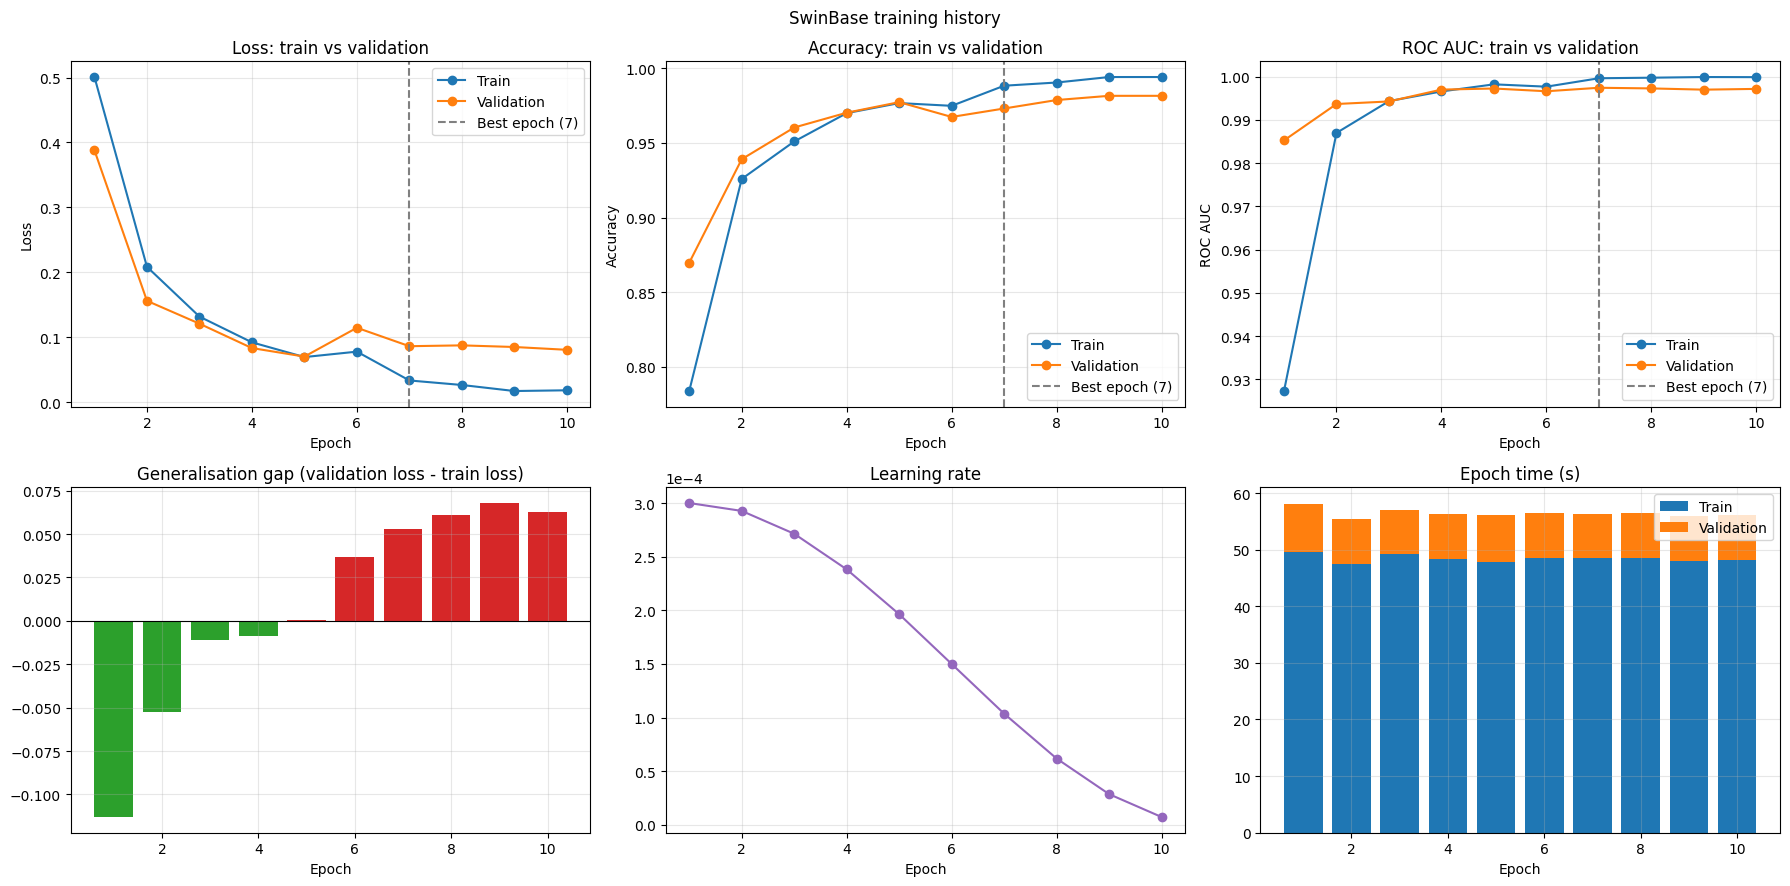

Saved plot: /kaggle/working/outputs/classification-swinbase/plots/07_training_curves.png


In [23]:
# Training curves
epochs_axis = history_df["epoch"]
best_epoch = training_summary["best_epoch"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, metric, label in zip(
    axes[0], ["loss", "acc", "auc"], ["Loss", "Accuracy", "ROC AUC"]
):
    ax.plot(epochs_axis, history_df[f"train_{metric}"], marker="o", label="Train")
    ax.plot(epochs_axis, history_df[f"val_{metric}"], marker="o", label="Validation")
    ax.axvline(
        best_epoch, color="grey", linestyle="--", label=f"Best epoch ({best_epoch})"
    )
    ax.set_title(f"{label}: train vs validation")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(label)
    ax.legend()

generalisation_gap = history_df["val_loss"] - history_df["train_loss"]
axes[1, 0].bar(
    epochs_axis,
    generalisation_gap,
    color=np.where(generalisation_gap > 0, "tab:red", "tab:green"),
)
axes[1, 0].axhline(0, color="black", linewidth=0.8)
axes[1, 0].set_title("Generalisation gap (validation loss - train loss)")
axes[1, 0].set_xlabel("Epoch")

axes[1, 1].plot(epochs_axis, history_df["lr"], marker="o", color="tab:purple")
axes[1, 1].set_title("Learning rate")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

axes[1, 2].bar(epochs_axis, history_df["train_time_s"], label="Train")
axes[1, 2].bar(
    epochs_axis,
    history_df["val_time_s"],
    bottom=history_df["train_time_s"],
    label="Validation",
)
axes[1, 2].set_title("Epoch time (s)")
axes[1, 2].set_xlabel("Epoch")
axes[1, 2].legend()

fig.suptitle(f"{MODEL_NAME} training history")
fig.tight_layout()
save_fig(fig, "07_training_curves")

## Testing

Loads the best checkpoint and evaluates it on the unseen test set.

In [24]:
# ================= TEST =================
state_dict = torch.load("/kaggle/working/best_swinbase_multi_class.pth")

if torch.cuda.device_count() > 1:
    model.module.load_state_dict(state_dict)
else:
    model.load_state_dict(state_dict)

model.eval()

test_loss, test_acc, test_auc = run_epoch(test_loader, training=False)

print("\n===== FINAL UNSEEN TEST RESULTS =====")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test AUC: {test_auc:.4f}")

Val/Test:   0%|          | 0/12 [00:00<?, ?it/s]


===== FINAL UNSEEN TEST RESULTS =====
Test Loss: 0.0377
Test Accuracy: 0.9858
Test AUC: 0.9993


## Save final model

Saves the model weights (best checkpoint) to `/kaggle/working/`.

In [25]:
# ================= SAVE FINAL MODEL =================
final_state = (
    model.module.state_dict() if torch.cuda.device_count() > 1 else model.state_dict()
)
torch.save(final_state, "/kaggle/working/final_swinbase_brain_tumor_multi_class.pth")

print("Final model saved.")

Final model saved.


## Collect predictions

Runs the best checkpoint (already loaded by the testing cell) on the validation and test sets using a single-GPU
copy of the model, and saves per-image predictions.

In [26]:
# Collect predictions on validation and test sets
eval_model = copy.deepcopy(unwrap_model(model)).to(DEVICE).eval()


@torch.no_grad()
def collect_predictions(net, loader, desc):
    prob_batches, label_batches = [], []
    for batch_images, batch_labels in tqdm(loader, desc=desc):
        batch_images = batch_images.to(DEVICE)
        with torch.amp.autocast(
            device_type=DEVICE.type, enabled=torch.cuda.is_available()
        ):
            logits = net(batch_images)
        logits = logits.float()
        if logits.shape[1] == 1:
            positive = torch.sigmoid(logits[:, 0])
            probs = torch.stack([1 - positive, positive], dim=1)
        else:
            probs = torch.softmax(logits, dim=1)
        prob_batches.append(probs.cpu())
        label_batches.append(batch_labels.cpu())
    probs = torch.cat(prob_batches).double().numpy()
    probs = probs / probs.sum(axis=1, keepdims=True)
    return probs, torch.cat(label_batches).numpy().astype(int)


predictions = {}
for split_name, loader, frame in [
    ("val", val_loader, val_df),
    ("test", test_loader, test_df),
]:
    sync_cuda()
    start = time.perf_counter()
    split_probs, split_true = collect_predictions(
        eval_model, loader, f"Predicting {split_name}"
    )
    sync_cuda()
    elapsed = time.perf_counter() - start

    split_pred = split_probs.argmax(axis=1)
    pred_frame = pd.DataFrame(
        {
            "path": frame["path"].values,
            "true_label": split_true,
            "true_class": [CLASS_NAMES[i] for i in split_true],
            "pred_label": split_pred,
            "pred_class": [CLASS_NAMES[i] for i in split_pred],
            "confidence": split_probs.max(axis=1),
            "correct": split_true == split_pred,
        }
    )
    for class_idx, class_name in enumerate(CLASS_NAMES):
        pred_frame[f"prob_{class_name.lower().replace(' ', '_')}"] = split_probs[
            :, class_idx
        ]

    predictions[split_name] = {
        "probs": split_probs,
        "y_true": split_true,
        "y_pred": split_pred,
        "frame": pred_frame,
        "seconds": elapsed,
    }
    save_table(pred_frame, f"predictions_{split_name}")
    print(f"{split_name}: {len(split_true)} images in {elapsed:.2f}s")

Predicting val:   0%|          | 0/12 [00:00<?, ?it/s]

Saved table: /kaggle/working/outputs/classification-swinbase/metrics/predictions_val.csv
val: 706 images in 6.55s


Predicting test:   0%|          | 0/12 [00:00<?, ?it/s]

Saved table: /kaggle/working/outputs/classification-swinbase/metrics/predictions_test.csv
test: 706 images in 5.97s


## Detailed metrics

Accuracy, balanced accuracy, precision, recall, specificity, F1, MCC, Cohen's kappa, ROC AUC, PR AUC, log loss,
Brier score and expected calibration error for validation and test, plus per-class metrics and classification reports.

In [27]:
# Detailed metrics
def safe_div(numerator, denominator):
    return float(numerator / denominator) if denominator else 0.0


def safe_score(fn, *args, **kwargs):
    try:
        return float(fn(*args, **kwargs))
    except ValueError:
        return float("nan")


def calibration_table(y_true, probs, n_bins=15):
    confidence = probs.max(axis=1)
    correct = probs.argmax(axis=1) == y_true
    edges = np.linspace(0, 1, n_bins + 1)
    rows = []
    for low, high in zip(edges[:-1], edges[1:]):
        mask = (confidence > low) & (confidence <= high)
        rows.append(
            {
                "bin_low": low,
                "bin_high": high,
                "count": int(mask.sum()),
                "mean_confidence": confidence[mask].mean() if mask.any() else np.nan,
                "accuracy": correct[mask].mean() if mask.any() else np.nan,
            }
        )
    return pd.DataFrame(rows)


def expected_calibration_error(y_true, probs, n_bins=15):
    table = calibration_table(y_true, probs, n_bins).dropna()
    weights = table["count"] / len(y_true)
    return float((weights * (table["accuracy"] - table["mean_confidence"]).abs()).sum())


def per_class_metrics(y_true, probs):
    y_pred = probs.argmax(axis=1)
    cm = skm.confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    rows = []
    for k, class_name in enumerate(CLASS_NAMES):
        tp = cm[k, k]
        fn = cm[k].sum() - tp
        fp = cm[:, k].sum() - tp
        tn = cm.sum() - tp - fn - fp
        y_binary = (y_true == k).astype(int)
        rows.append(
            {
                "class": class_name,
                "support": int(cm[k].sum()),
                "tp": int(tp),
                "fp": int(fp),
                "fn": int(fn),
                "tn": int(tn),
                "precision": safe_div(tp, tp + fp),
                "recall_sensitivity": safe_div(tp, tp + fn),
                "specificity": safe_div(tn, tn + fp),
                "npv": safe_div(tn, tn + fn),
                "fpr": safe_div(fp, fp + tn),
                "fnr": safe_div(fn, fn + tp),
                "f1": safe_div(2 * tp, 2 * tp + fp + fn),
                "roc_auc": safe_score(skm.roc_auc_score, y_binary, probs[:, k]),
                "average_precision": safe_score(
                    skm.average_precision_score, y_binary, probs[:, k]
                ),
            }
        )
    return pd.DataFrame(rows)


def compute_metrics(y_true, probs):
    y_pred = probs.argmax(axis=1)
    labels = list(range(NUM_CLASSES))
    one_hot = np.eye(NUM_CLASSES)[y_true]
    result = {
        "samples": len(y_true),
        "accuracy": skm.accuracy_score(y_true, y_pred),
        "balanced_accuracy": skm.balanced_accuracy_score(y_true, y_pred),
        "error_rate": 1 - skm.accuracy_score(y_true, y_pred),
    }
    for average in ("macro", "weighted", "micro"):
        result[f"precision_{average}"] = skm.precision_score(
            y_true, y_pred, labels=labels, average=average, zero_division=0
        )
        result[f"recall_{average}"] = skm.recall_score(
            y_true, y_pred, labels=labels, average=average, zero_division=0
        )
        result[f"f1_{average}"] = skm.f1_score(
            y_true, y_pred, labels=labels, average=average, zero_division=0
        )
    result["mcc"] = skm.matthews_corrcoef(y_true, y_pred)
    result["cohen_kappa"] = skm.cohen_kappa_score(y_true, y_pred)
    result["jaccard_macro"] = skm.jaccard_score(
        y_true, y_pred, labels=labels, average="macro", zero_division=0
    )
    result["log_loss"] = skm.log_loss(y_true, probs, labels=labels)
    result["brier_score"] = float(np.mean(np.sum((probs - one_hot) ** 2, axis=1)))
    result["expected_calibration_error"] = expected_calibration_error(y_true, probs)
    result["mean_confidence"] = float(probs.max(axis=1).mean())

    if IS_BINARY:
        positive = per_class_metrics(y_true, probs).iloc[1]
        p1 = probs[:, 1]
        result.update(
            {
                "tp": positive["tp"],
                "fp": positive["fp"],
                "fn": positive["fn"],
                "tn": positive["tn"],
                "precision": positive["precision"],
                "recall_sensitivity": positive["recall_sensitivity"],
                "specificity": positive["specificity"],
                "npv": positive["npv"],
                "fpr": positive["fpr"],
                "fnr": positive["fnr"],
                "f1": positive["f1"],
                "f2": skm.fbeta_score(y_true, y_pred, beta=2, zero_division=0),
                "roc_auc": safe_score(skm.roc_auc_score, y_true, p1),
                "pr_auc_average_precision": safe_score(
                    skm.average_precision_score, y_true, p1
                ),
                "brier_score_positive_class": skm.brier_score_loss(y_true, p1),
            }
        )
        fpr, tpr, thresholds = skm.roc_curve(y_true, p1)
        best = int(np.argmax(tpr - fpr))
        result["youden_j"] = float(tpr[best] - fpr[best])
        result["youden_optimal_threshold"] = float(min(thresholds[best], 1.0))
        result["sensitivity_at_youden_threshold"] = float(tpr[best])
        result["specificity_at_youden_threshold"] = float(1 - fpr[best])
    else:
        result["roc_auc_ovr_macro"] = safe_score(
            skm.roc_auc_score, y_true, probs, multi_class="ovr", average="macro"
        )
        result["roc_auc_ovr_weighted"] = safe_score(
            skm.roc_auc_score, y_true, probs, multi_class="ovr", average="weighted"
        )
        result["roc_auc_ovo_macro"] = safe_score(
            skm.roc_auc_score, y_true, probs, multi_class="ovo", average="macro"
        )
        result["pr_auc_macro"] = safe_score(
            skm.average_precision_score, one_hot, probs, average="macro"
        )
        result["pr_auc_micro"] = safe_score(
            skm.average_precision_score, one_hot, probs, average="micro"
        )
        result["specificity_macro"] = float(
            per_class_metrics(y_true, probs)["specificity"].mean()
        )
        result["top_2_accuracy"] = skm.top_k_accuracy_score(
            y_true, probs, k=2, labels=labels
        )
    return {
        key: _to_builtin(value) if isinstance(value, np.generic) else value
        for key, value in result.items()
    }


metrics_by_split = {}
per_class_by_split = {}
for split_name in tqdm(["val", "test"], desc="Computing metrics"):
    split = predictions[split_name]
    metrics_by_split[split_name] = compute_metrics(split["y_true"], split["probs"])
    per_class_by_split[split_name] = per_class_metrics(split["y_true"], split["probs"])
    report = skm.classification_report(
        split["y_true"],
        split["y_pred"],
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
    save_json(metrics_by_split[split_name], f"metrics_{split_name}")
    save_table(per_class_by_split[split_name], f"per_class_metrics_{split_name}")
    save_text(report, f"classification_report_{split_name}")
    print(f"\n===== Classification report ({split_name}) =====\n{report}")

metrics_table = pd.DataFrame(metrics_by_split).rename(columns={"val": "validation"})
save_table(metrics_table, "metrics_summary", index=True)
display(metrics_table)
display(per_class_by_split["test"].round(4))

Computing metrics:   0%|          | 0/2 [00:00<?, ?it/s]

Saved JSON: /kaggle/working/outputs/classification-swinbase/metrics/metrics_val.json
Saved table: /kaggle/working/outputs/classification-swinbase/metrics/per_class_metrics_val.csv
Saved text: /kaggle/working/outputs/classification-swinbase/metrics/classification_report_val.txt

===== Classification report (val) =====
              precision    recall  f1-score   support

      Glioma     0.9735    0.9800    0.9767       300
  Meningioma     0.9684    0.9436    0.9558       195
   Pituitary     0.9766    0.9905    0.9835       211

    accuracy                         0.9731       706
   macro avg     0.9729    0.9714    0.9720       706
weighted avg     0.9730    0.9731    0.9730       706

Saved JSON: /kaggle/working/outputs/classification-swinbase/metrics/metrics_test.json
Saved table: /kaggle/working/outputs/classification-swinbase/metrics/per_class_metrics_test.csv
Saved text: /kaggle/working/outputs/classification-swinbase/metrics/classification_report_test.txt

===== Classificati

,validation,test
samples,706.000000,706.000000
accuracy,0.973088,0.985836
balanced_accuracy,0.971370,0.984172
error_rate,0.026912,0.014164
precision_macro,0.972856,0.985417
recall_macro,0.971370,0.984172
f1_macro,0.972039,0.984670
precision_weighted,0.973038,0.985925
recall_weighted,0.973088,0.985836
f1_weighted,0.972999,0.985773


,class,support,tp,fp,fn,tn,precision,recall_sensitivity,specificity,npv,fpr,fnr,f1,roc_auc,average_precision
0,Glioma,300,298,3,2,403,0.9900,0.9933,0.9926,0.9951,0.0074,0.0067,0.9917,0.9998,0.9998
1,Meningioma,196,188,2,8,508,0.9895,0.9592,0.9961,0.9845,0.0039,0.0408,0.9741,0.9986,0.9972
2,Pituitary,210,210,5,0,491,0.9767,1.0000,0.9899,1.0000,0.0101,0.0000,0.9882,0.9994,0.9985


## Confusion matrices

Counts and row-normalised confusion matrices for validation (top) and test (bottom).

Saved table: /kaggle/working/outputs/classification-swinbase/metrics/confusion_matrix_val.csv
Saved table: /kaggle/working/outputs/classification-swinbase/metrics/confusion_matrix_test.csv


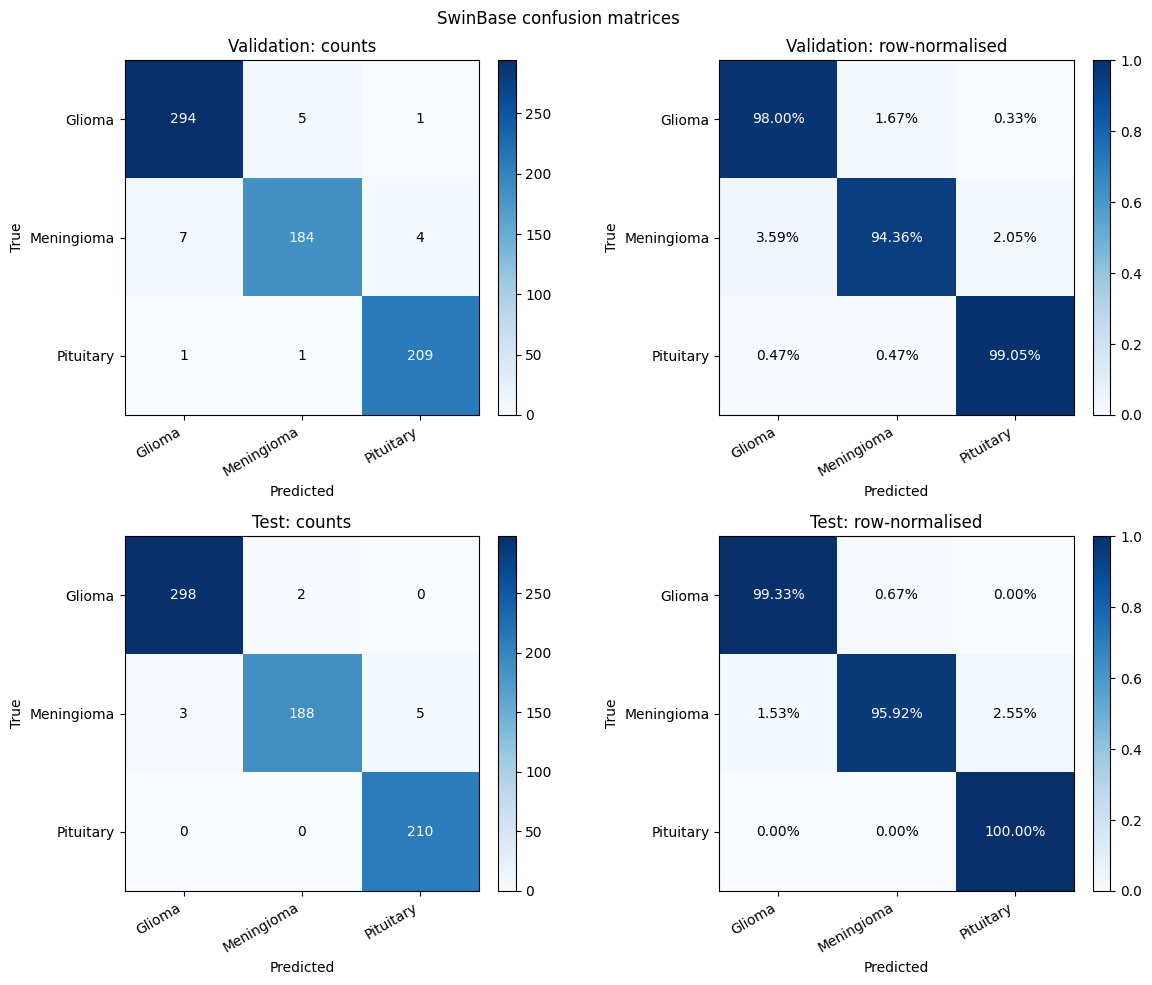

Saved plot: /kaggle/working/outputs/classification-swinbase/plots/08_confusion_matrices.png


In [28]:
# Confusion matrices: validation (top) and test (bottom)
def plot_confusion(ax, cm, title, normalise):
    data = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None) if normalise else cm
    image = ax.imshow(data, cmap="Blues", vmin=0, vmax=1 if normalise else cm.max())
    ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=30, ha="right")
    ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    ax.grid(False)
    threshold = data.max() / 2
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            text = f"{data[i, j]:.2%}" if normalise else f"{int(data[i, j])}"
            ax.text(
                j,
                i,
                text,
                ha="center",
                va="center",
                color="white" if data[i, j] > threshold else "black",
            )
    plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04)


fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for row, (split_name, split_label) in enumerate(
    [("val", "Validation"), ("test", "Test")]
):
    cm = skm.confusion_matrix(
        predictions[split_name]["y_true"],
        predictions[split_name]["y_pred"],
        labels=list(range(NUM_CLASSES)),
    )
    save_table(
        pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES),
        f"confusion_matrix_{split_name}",
        index=True,
    )
    plot_confusion(axes[row, 0], cm, f"{split_label}: counts", normalise=False)
    plot_confusion(axes[row, 1], cm, f"{split_label}: row-normalised", normalise=True)
fig.suptitle(f"{MODEL_NAME} confusion matrices")
fig.tight_layout()
save_fig(fig, "08_confusion_matrices")

## ROC and precision-recall curves

ROC and precision-recall curves for validation (top) and test (bottom).

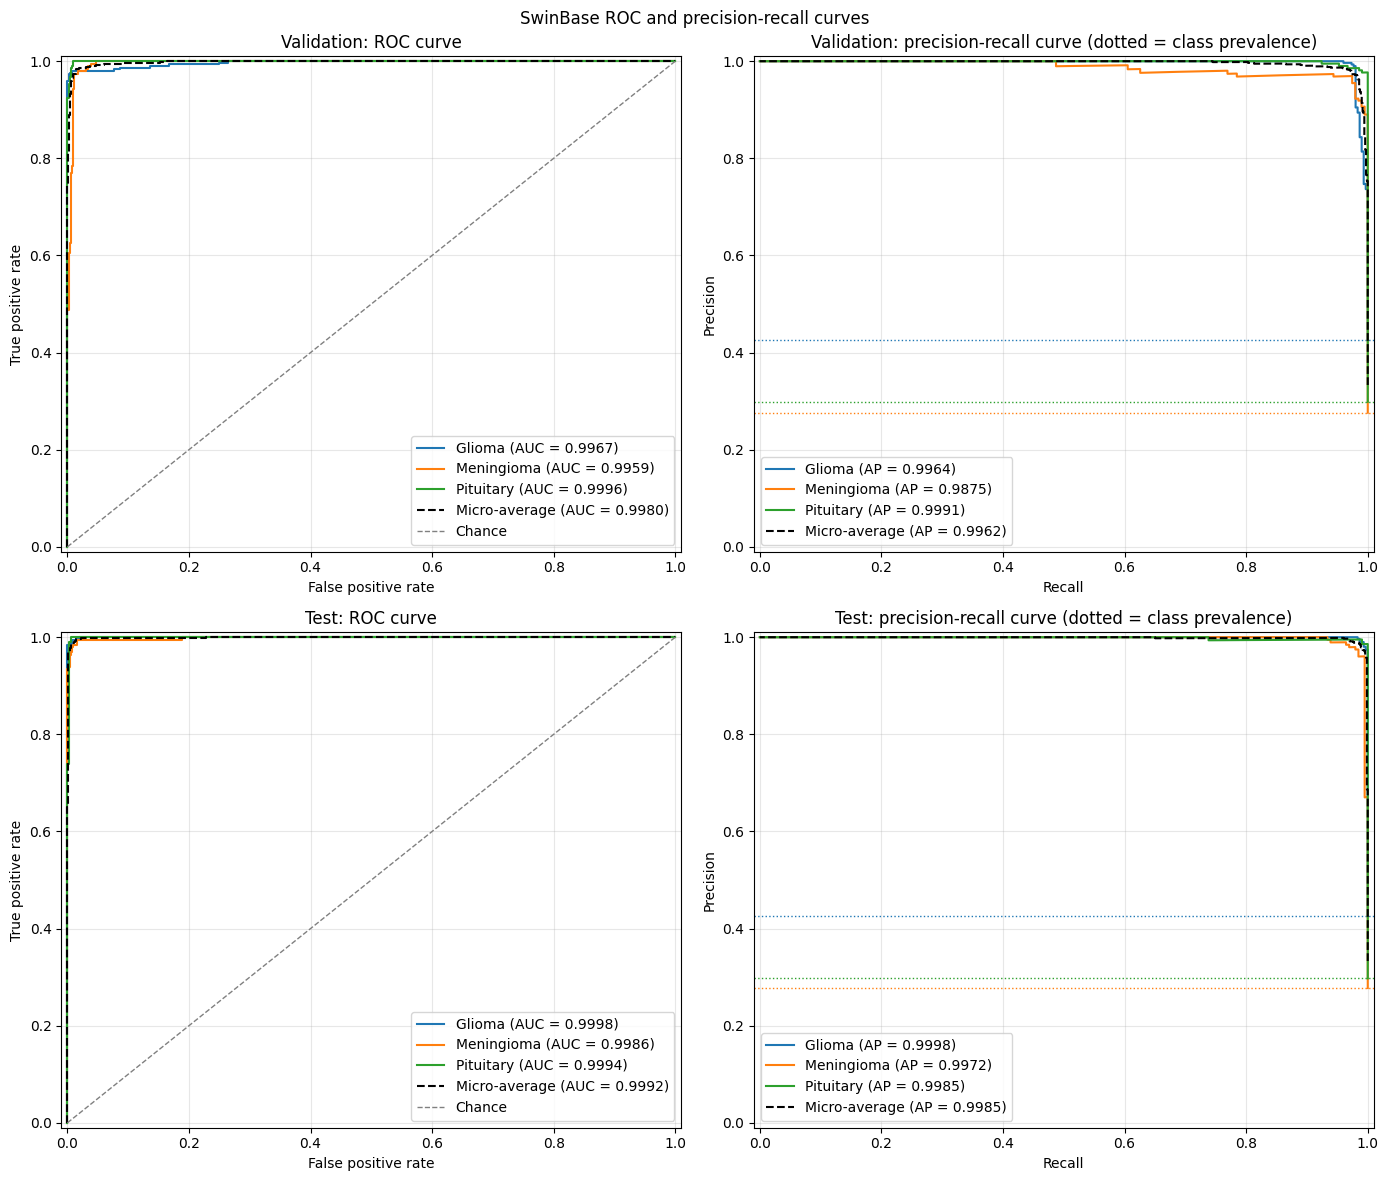

Saved plot: /kaggle/working/outputs/classification-swinbase/plots/09_roc_pr_curves.png


In [29]:
# ROC and precision-recall curves: validation (top) and test (bottom)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for row, (split_name, split_label) in enumerate(
    [("val", "Validation"), ("test", "Test")]
):
    y_true = predictions[split_name]["y_true"]
    probs = predictions[split_name]["probs"]
    ax_roc, ax_pr = axes[row]
    curve_classes = [1] if IS_BINARY else range(NUM_CLASSES)

    for k in curve_classes:
        y_binary = (y_true == k).astype(int)
        fpr, tpr, _ = skm.roc_curve(y_binary, probs[:, k])
        precision, recall, _ = skm.precision_recall_curve(y_binary, probs[:, k])
        ax_roc.plot(
            fpr,
            tpr,
            color=CLASS_COLOURS[k],
            label=f"{CLASS_NAMES[k]} (AUC = {skm.auc(fpr, tpr):.4f})",
        )
        ax_pr.plot(
            recall,
            precision,
            color=CLASS_COLOURS[k],
            label=f"{CLASS_NAMES[k]} (AP = {skm.average_precision_score(y_binary, probs[:, k]):.4f})",
        )
        ax_pr.axhline(
            y_binary.mean(), color=CLASS_COLOURS[k], linestyle=":", linewidth=1
        )

    if not IS_BINARY:
        one_hot = np.eye(NUM_CLASSES)[y_true]
        fpr, tpr, _ = skm.roc_curve(one_hot.ravel(), probs.ravel())
        precision, recall, _ = skm.precision_recall_curve(
            one_hot.ravel(), probs.ravel()
        )
        ax_roc.plot(
            fpr,
            tpr,
            color="black",
            linestyle="--",
            label=f"Micro-average (AUC = {skm.auc(fpr, tpr):.4f})",
        )
        ax_pr.plot(
            recall,
            precision,
            color="black",
            linestyle="--",
            label=f"Micro-average (AP = {skm.average_precision_score(one_hot, probs, average='micro'):.4f})",
        )

    ax_roc.plot(
        [0, 1], [0, 1], color="grey", linestyle="--", linewidth=1, label="Chance"
    )
    ax_roc.set_title(f"{split_label}: ROC curve")
    ax_roc.set_xlabel("False positive rate")
    ax_roc.set_ylabel("True positive rate")
    ax_roc.legend(loc="lower right")
    ax_pr.set_title(
        f"{split_label}: precision-recall curve (dotted = class prevalence)"
    )
    ax_pr.set_xlabel("Recall")
    ax_pr.set_ylabel("Precision")
    ax_pr.legend(loc="lower left")
    for ax in (ax_roc, ax_pr):
        ax.set_xlim(-0.01, 1.01)
        ax.set_ylim(-0.01, 1.01)

fig.suptitle(f"{MODEL_NAME} ROC and precision-recall curves")
fig.tight_layout()
save_fig(fig, "09_roc_pr_curves")

## Calibration

Reliability diagram (top) and confidence distribution for correct vs incorrect predictions (bottom).

Saved table: /kaggle/working/outputs/classification-swinbase/metrics/calibration_bins_val.csv
Saved table: /kaggle/working/outputs/classification-swinbase/metrics/calibration_bins_test.csv


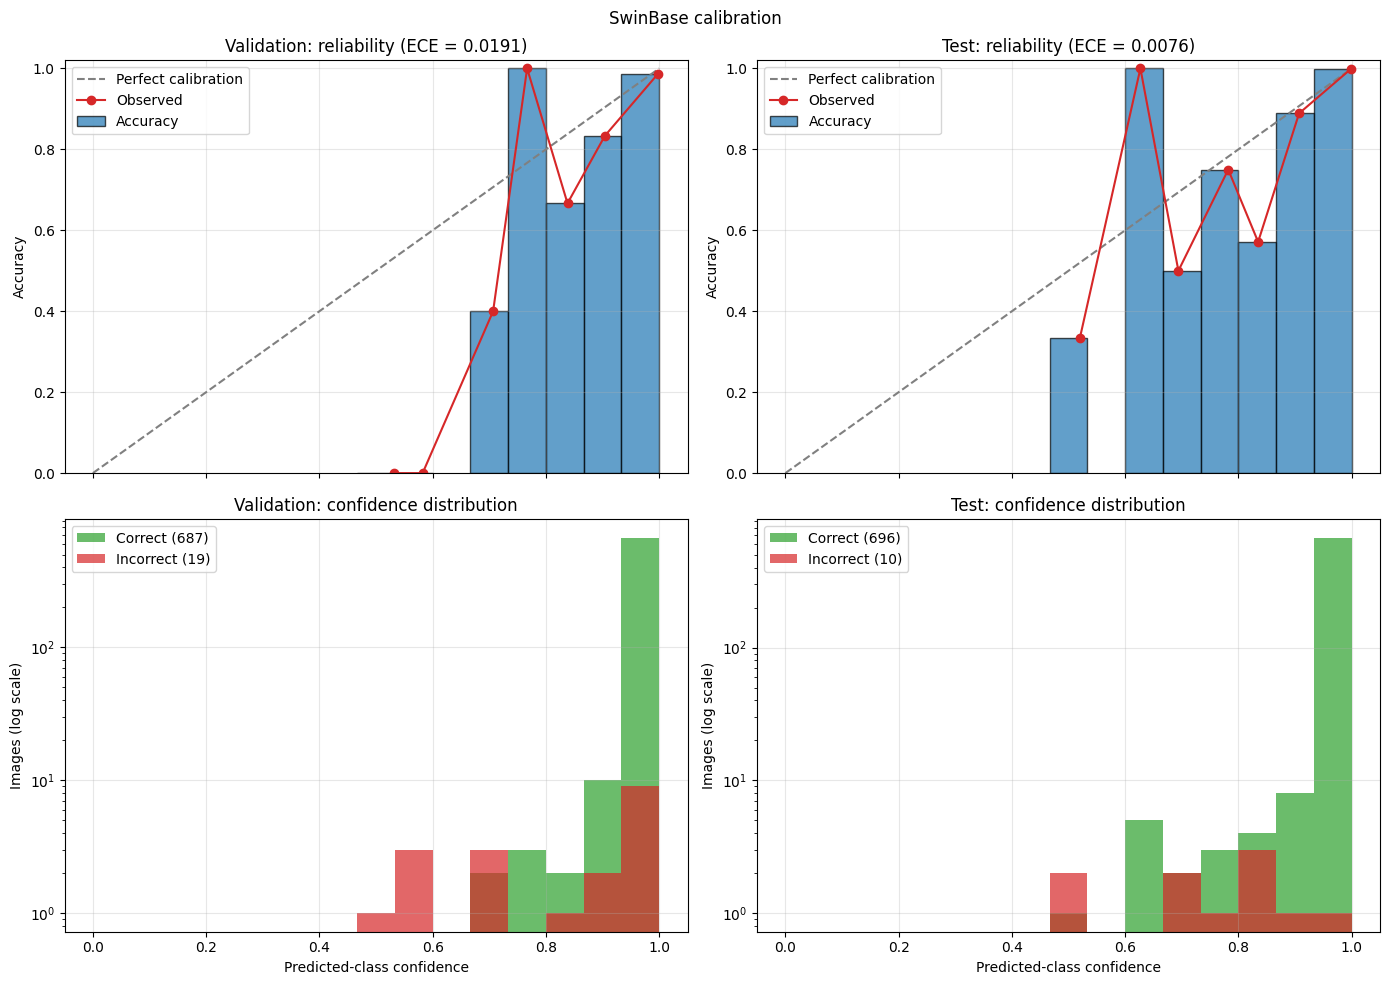

Saved plot: /kaggle/working/outputs/classification-swinbase/plots/10_calibration.png


In [30]:
# Calibration: reliability diagram (top) and confidence distribution (bottom)
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
bin_edges = np.linspace(0, 1, 16)
for col, (split_name, split_label) in enumerate(
    [("val", "Validation"), ("test", "Test")]
):
    y_true = predictions[split_name]["y_true"]
    probs = predictions[split_name]["probs"]
    table = calibration_table(y_true, probs)
    save_table(table, f"calibration_bins_{split_name}")
    valid = table.dropna()

    ax = axes[0, col]
    ax.bar(
        (valid["bin_low"] + valid["bin_high"]) / 2,
        valid["accuracy"],
        width=1 / 15,
        edgecolor="black",
        alpha=0.7,
        label="Accuracy",
    )
    ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Perfect calibration")
    ax.plot(
        valid["mean_confidence"],
        valid["accuracy"],
        marker="o",
        color="tab:red",
        label="Observed",
    )
    ax.set_title(
        f"{split_label}: reliability (ECE = {metrics_by_split[split_name]['expected_calibration_error']:.4f})"
    )
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1.02)
    ax.legend(loc="upper left")

    confidence = probs.max(axis=1)
    correct = predictions[split_name]["y_pred"] == y_true
    ax = axes[1, col]
    ax.hist(
        confidence[correct],
        bins=bin_edges,
        alpha=0.7,
        label=f"Correct ({correct.sum()})",
        color="tab:green",
    )
    ax.hist(
        confidence[~correct],
        bins=bin_edges,
        alpha=0.7,
        label=f"Incorrect ({(~correct).sum()})",
        color="tab:red",
    )
    ax.set_yscale("log")
    ax.set_title(f"{split_label}: confidence distribution")
    ax.set_xlabel("Predicted-class confidence")
    ax.set_ylabel("Images (log scale)")
    ax.legend(loc="upper left")

fig.suptitle(f"{MODEL_NAME} calibration")
fig.tight_layout()
save_fig(fig, "10_calibration")

## Per-class metrics

Precision, recall, specificity and F1 for each class on the test set.

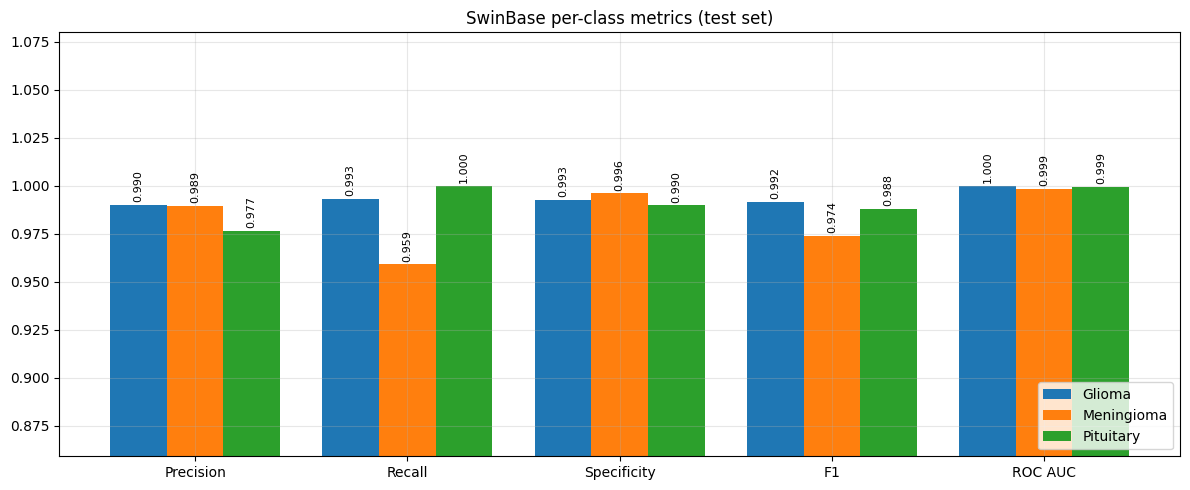

Saved plot: /kaggle/working/outputs/classification-swinbase/plots/11_per_class_metrics.png


In [31]:
# Per-class metrics (test set)
test_per_class = per_class_by_split["test"]
metric_columns = ["precision", "recall_sensitivity", "specificity", "f1", "roc_auc"]
metric_labels = ["Precision", "Recall", "Specificity", "F1", "ROC AUC"]

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(metric_columns))
width = 0.8 / NUM_CLASSES
for class_idx, class_name in enumerate(CLASS_NAMES):
    values = test_per_class.loc[class_idx, metric_columns].astype(float).values
    bars = ax.bar(
        x + (class_idx - (NUM_CLASSES - 1) / 2) * width,
        values,
        width,
        color=CLASS_COLOURS[class_idx],
        label=class_name,
    )
    ax.bar_label(
        bars, labels=[f"{v:.3f}" for v in values], fontsize=8, rotation=90, padding=2
    )
ax.set_xticks(x, metric_labels)
ax.set_ylim(
    max(0.0, np.nanmin(test_per_class[metric_columns].astype(float).values) - 0.1), 1.08
)
ax.set_title(f"{MODEL_NAME} per-class metrics (test set)")
ax.legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "11_per_class_metrics")

## Prediction samples

Correct predictions (top row) and misclassified predictions (bottom row) from the test set.

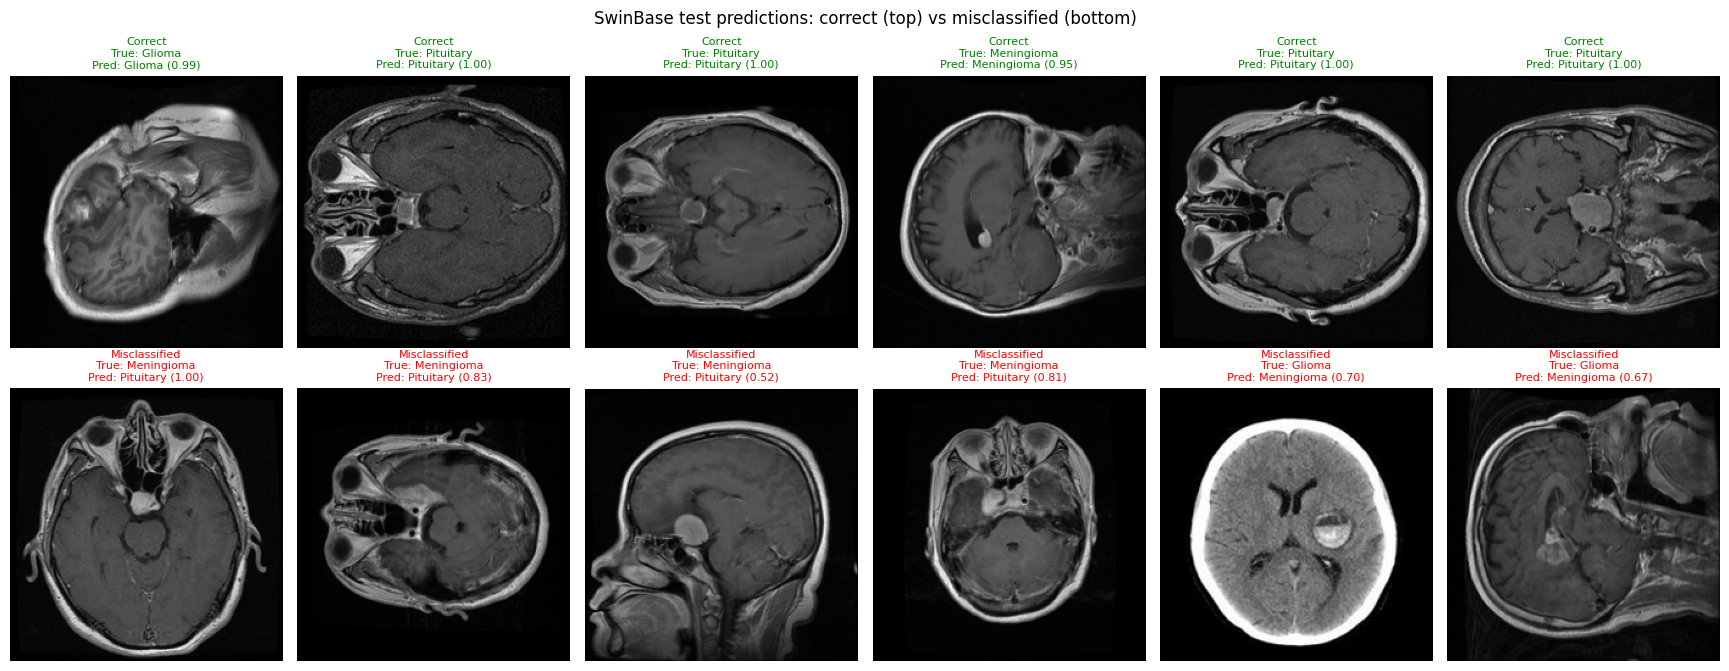

Saved plot: /kaggle/working/outputs/classification-swinbase/plots/12_prediction_samples.png


In [32]:
# Prediction samples: correct (top) vs misclassified (bottom)
SAMPLE_COLUMNS = 6
test_frame = predictions["test"]["frame"]
sample_rng = np.random.RandomState(SEED)
sample_sets = []
for is_correct in (True, False):
    candidates = test_frame[test_frame["correct"] == is_correct]
    chosen = sample_rng.choice(
        len(candidates), size=min(SAMPLE_COLUMNS, len(candidates)), replace=False
    )
    sample_sets.append(candidates.iloc[chosen])

fig, axes = plt.subplots(
    2, SAMPLE_COLUMNS, figsize=(2.9 * SAMPLE_COLUMNS, 7), squeeze=False
)
for row, (sample_frame, row_label) in enumerate(
    zip(sample_sets, ["Correct", "Misclassified"])
):
    for col in range(SAMPLE_COLUMNS):
        ax = axes[row, col]
        ax.axis("off")
        if col >= len(sample_frame):
            if col == 0:
                ax.text(
                    0.5,
                    0.5,
                    f"No {row_label.lower()} predictions",
                    ha="center",
                    va="center",
                )
            continue
        item = sample_frame.iloc[col]
        with Image.open(item["path"]) as img:
            ax.imshow(img.convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
        ax.set_title(
            f"{row_label}\nTrue: {item['true_class']}\nPred: {item['pred_class']} ({item['confidence']:.2f})",
            fontsize=8,
            color="green" if item["correct"] else "red",
        )
fig.suptitle(f"{MODEL_NAME} test predictions: correct (top) vs misclassified (bottom)")
fig.tight_layout()
save_fig(fig, "12_prediction_samples")

## Grad-CAM implementation

Gradient-weighted class activation mapping on the target layer set in the notebook settings.
Works with CNN feature maps, channels-last feature maps and transformer token sequences.

In [33]:
# Grad-CAM implementation
def to_nchw(tensor):
    """Convert activations to (batch, channels, height, width)."""
    if tensor.dim() == 3:  # transformer tokens: (batch, tokens, channels)
        tokens = tensor.shape[1]
        side = int(round(math.sqrt(tokens)))
        if side * side != tokens:  # drop the class token
            tensor = tensor[:, 1:, :]
            side = int(round(math.sqrt(tensor.shape[1])))
        return tensor.reshape(tensor.shape[0], side, side, tensor.shape[2]).permute(
            0, 3, 1, 2
        )
    if (
        tensor.dim() == 4
        and tensor.shape[1] == tensor.shape[2]
        and tensor.shape[3] != tensor.shape[1]
    ):
        return tensor.permute(0, 3, 1, 2)  # channels-last feature map
    return tensor


class GradCAM:
    def __init__(self, net, target_layer):
        self.net = net
        self.activations = None
        self.gradients = None
        self.handle = target_layer.register_forward_hook(self._forward_hook)

    def _forward_hook(self, module, inputs, output):
        output = output[0] if isinstance(output, (tuple, list)) else output
        self.activations = output
        if output.requires_grad:
            output.register_hook(self._save_gradient)

    def _save_gradient(self, grad):
        self.gradients = grad

    def remove(self):
        self.handle.remove()

    def __call__(self, image_tensor, class_idx=None):
        self.net.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = self.net(
                image_tensor.unsqueeze(0).to(DEVICE).requires_grad_(True)
            ).float()
            if logits.shape[1] == 1:
                positive = torch.sigmoid(logits[0, 0])
                probs = torch.stack([1 - positive, positive])
                predicted = int(positive.item() > 0.5)
                class_idx = predicted if class_idx is None else class_idx
                score = logits[0, 0] if class_idx == 1 else -logits[0, 0]
            else:
                probs = torch.softmax(logits[0], dim=0)
                predicted = int(probs.argmax().item())
                class_idx = predicted if class_idx is None else class_idx
                score = logits[0, class_idx]
            score.backward()

        activations = to_nchw(self.activations.detach().float())
        gradients = to_nchw(self.gradients.detach().float())
        weights = gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(
            cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False
        )[0, 0]
        cam = cam - cam.min()
        cam = cam / cam.max() if cam.max() > 0 else cam
        return cam.cpu().numpy(), predicted, probs.detach().cpu().numpy()


gradcam_model = copy.deepcopy(eval_model).float().eval()
print("Grad-CAM target layer:", type(get_gradcam_target_layer(gradcam_model)).__name__)

Grad-CAM target layer: LayerNorm


## Grad-CAM visualisations

For each test image: the input (top), the Grad-CAM heatmap for the predicted class (middle) and the overlay
(bottom), stacked in one column. Shown for high-confidence correct predictions and for misclassifications.

Grad-CAM: most confident correct predictions:   0%|          | 0/6 [00:00<?, ?it/s]

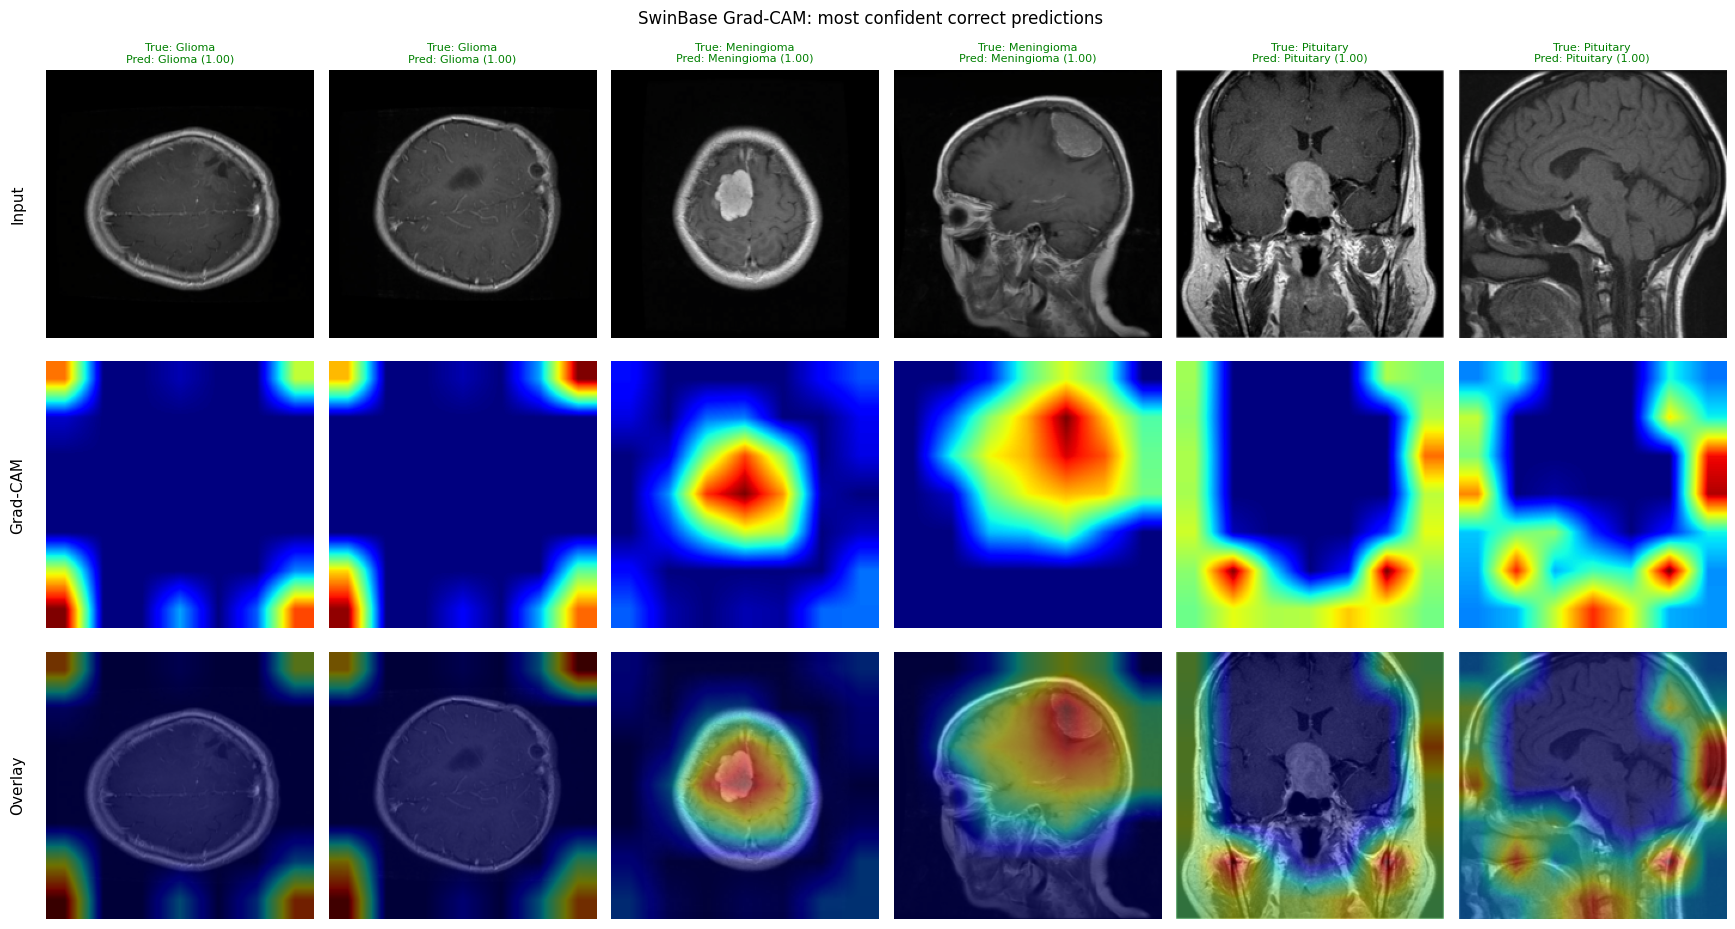

Saved plot: /kaggle/working/outputs/classification-swinbase/plots/13_gradcam_correct.png


Grad-CAM: most confident misclassifications:   0%|          | 0/6 [00:00<?, ?it/s]

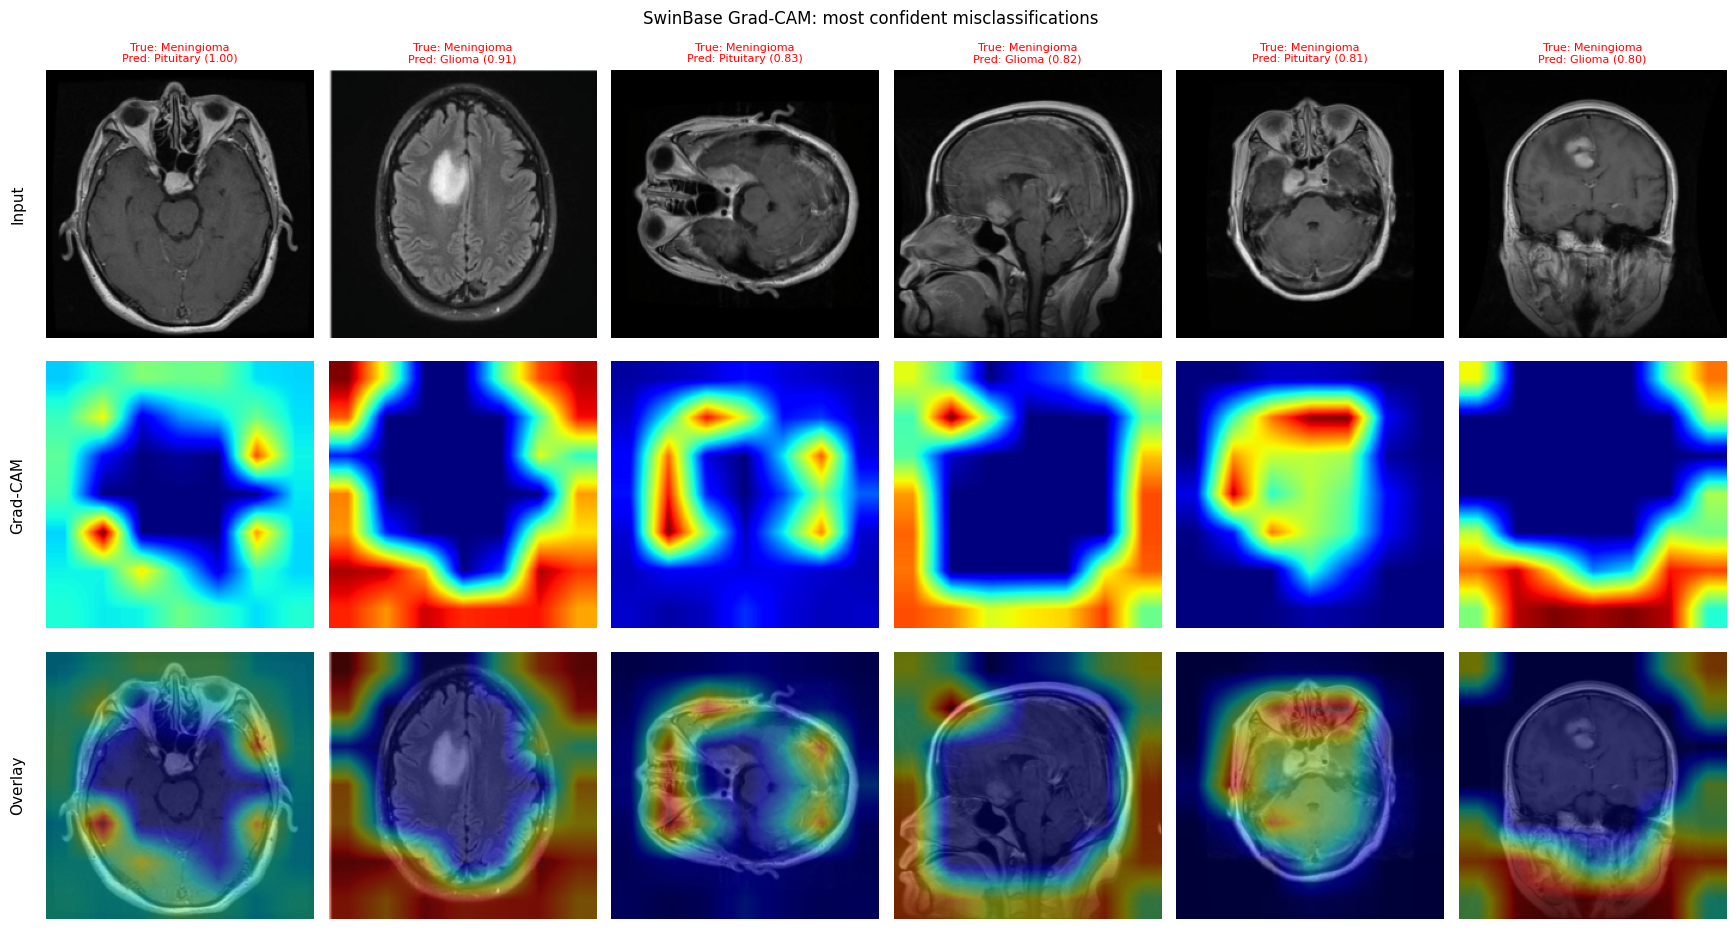

Saved plot: /kaggle/working/outputs/classification-swinbase/plots/14_gradcam_misclassified.png


In [34]:
# Grad-CAM visualisations: input (top), heatmap (middle), overlay (bottom)
def plot_gradcam(sample_frame, title, name):
    if sample_frame.empty:
        print(f"Skipping '{title}': no samples.")
        return
    cam_engine = GradCAM(gradcam_model, get_gradcam_target_layer(gradcam_model))
    try:
        n_cols = len(sample_frame)
        fig, axes = plt.subplots(3, n_cols, figsize=(2.9 * n_cols, 9.6), squeeze=False)
        for col, item in enumerate(
            tqdm(sample_frame.to_dict("records"), desc=f"Grad-CAM: {title}")
        ):
            with Image.open(item["path"]) as img:
                image_tensor = val_tfms(img.convert("RGB"))
            cam, predicted, probs = cam_engine(image_tensor)
            image = denormalise(image_tensor)

            axes[0, col].imshow(image)
            axes[0, col].set_title(
                f"True: {item['true_class']}\nPred: {CLASS_NAMES[predicted]} ({probs[predicted]:.2f})",
                fontsize=8,
                color="green" if predicted == item["true_label"] else "red",
            )
            axes[1, col].imshow(cam, cmap="jet", vmin=0, vmax=1)
            axes[2, col].imshow(image)
            axes[2, col].imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
            for row in range(3):
                axes[row, col].axis("off")
        for row, label in enumerate(["Input", "Grad-CAM", "Overlay"]):
            axes[row, 0].text(
                -0.08,
                0.5,
                label,
                transform=axes[row, 0].transAxes,
                rotation=90,
                ha="right",
                va="center",
                fontsize=11,
            )
        fig.suptitle(f"{MODEL_NAME} Grad-CAM: {title}")
        fig.tight_layout()
        save_fig(fig, name)
    finally:
        cam_engine.remove()


test_frame = predictions["test"]["frame"]
GRADCAM_CORRECT_PER_CLASS = 2
GRADCAM_MISCLASSIFIED = 6
gradcam_correct = pd.concat(
    [
        test_frame[(test_frame["correct"]) & (test_frame["true_label"] == k)].nlargest(
            GRADCAM_CORRECT_PER_CLASS, "confidence"
        )
        for k in range(NUM_CLASSES)
    ]
)
gradcam_wrong = test_frame[~test_frame["correct"]].nlargest(
    GRADCAM_MISCLASSIFIED, "confidence"
)

gradcam_status = "ok"
try:
    plot_gradcam(
        gradcam_correct, "most confident correct predictions", "13_gradcam_correct"
    )
    plot_gradcam(
        gradcam_wrong, "most confident misclassifications", "14_gradcam_misclassified"
    )
except Exception as exc:
    gradcam_status = f"failed: {exc}"
    print("Grad-CAM failed; continuing so the remaining outputs are still produced.")
    traceback.print_exc()

## Inference benchmark

Single-image latency and batched throughput on synthetic input, plus end-to-end test-set inference speed.

In [35]:
# Inference benchmark
BENCHMARK_BATCH_SIZE = 32
LATENCY_ITERATIONS = 100
THROUGHPUT_ITERATIONS = 20


@torch.no_grad()
def time_forward(net, batch, iterations, warmup, desc):
    for _ in range(warmup):
        with torch.amp.autocast(
            device_type=DEVICE.type, enabled=torch.cuda.is_available()
        ):
            net(batch)
    sync_cuda()
    timings = []
    for _ in tqdm(range(iterations), desc=desc):
        start = time.perf_counter()
        with torch.amp.autocast(
            device_type=DEVICE.type, enabled=torch.cuda.is_available()
        ):
            net(batch)
        sync_cuda()
        timings.append(time.perf_counter() - start)
    return np.array(timings)


latency = time_forward(
    eval_model,
    torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE),
    LATENCY_ITERATIONS,
    10,
    "Latency (batch size 1)",
)
inference_benchmark = {
    "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "precision": "fp16 autocast" if torch.cuda.is_available() else "fp32",
    "latency_batch1_mean_ms": round(latency.mean() * 1000, 3),
    "latency_batch1_median_ms": round(np.median(latency) * 1000, 3),
    "latency_batch1_p95_ms": round(np.percentile(latency, 95) * 1000, 3),
    "latency_batch1_std_ms": round(latency.std() * 1000, 3),
    "throughput_batch1_images_per_s": round(1 / latency.mean(), 2),
    "benchmark_batch_size": BENCHMARK_BATCH_SIZE,
}
try:
    batch_timings = time_forward(
        eval_model,
        torch.randn(BENCHMARK_BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE, device=DEVICE),
        THROUGHPUT_ITERATIONS,
        3,
        f"Throughput (batch size {BENCHMARK_BATCH_SIZE})",
    )
    inference_benchmark["latency_batched_mean_ms"] = round(
        batch_timings.mean() * 1000, 3
    )
    inference_benchmark["throughput_batched_images_per_s"] = round(
        BENCHMARK_BATCH_SIZE / batch_timings.mean(), 2
    )
except torch.cuda.OutOfMemoryError:
    torch.cuda.empty_cache()
    print(
        f"Out of memory at batch size {BENCHMARK_BATCH_SIZE}; batched throughput skipped."
    )

inference_benchmark["test_set_images"] = len(predictions["test"]["y_true"])
inference_benchmark["test_set_end_to_end_s"] = round(predictions["test"]["seconds"], 3)
inference_benchmark["test_set_end_to_end_images_per_s"] = round(
    len(predictions["test"]["y_true"]) / predictions["test"]["seconds"], 2
)
if test_phase_seconds is not None:
    inference_benchmark["original_test_cell_seconds"] = round(test_phase_seconds, 3)

save_json(inference_benchmark, "inference_benchmark")
display(pd.Series(inference_benchmark, name="value").to_frame())

Latency (batch size 1):   0%|          | 0/100 [00:00<?, ?it/s]

Throughput (batch size 32):   0%|          | 0/20 [00:00<?, ?it/s]

Saved JSON: /kaggle/working/outputs/classification-swinbase/metrics/inference_benchmark.json


,value
device,Tesla T4
precision,fp16 autocast
latency_batch1_mean_ms,35.131
latency_batch1_median_ms,34.704
latency_batch1_p95_ms,37.852
latency_batch1_std_ms,2.565
throughput_batch1_images_per_s,28.47
benchmark_batch_size,32
latency_batched_mean_ms,158.098
throughput_batched_images_per_s,202.41


## Benchmark summary

One consolidated record for this model (configuration, model profile, training, inference and test metrics),
saved as JSON and single-row CSV so results from all notebooks can be concatenated.

In [36]:
# Benchmark summary
benchmark_summary = {
    "task": TASK,
    "model": MODEL_NAME,
    "run_name": RUN_NAME,
    "generated_at": datetime.now().isoformat(timespec="seconds"),
    "image_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "learning_rate": LR,
    "seed": SEED,
    "train_images": len(train_df),
    "val_images": len(val_df),
    "test_images": len(test_df),
    **{f"model_{k}": v for k, v in model_profile.items()},
    **{f"training_{k}": v for k, v in training_summary.items()},
    **{f"inference_{k}": v for k, v in inference_benchmark.items()},
    **{f"val_{k}": v for k, v in metrics_by_split["val"].items()},
    **{f"test_{k}": v for k, v in metrics_by_split["test"].items()},
    "gradcam_status": gradcam_status,
    "env_python": platform.python_version(),
    "env_torch": torch.__version__,
    "env_cuda": torch.version.cuda,
    "env_gpu_count": torch.cuda.device_count(),
    "env_gpu_names": ", ".join(
        torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())
    ),
}
save_json(benchmark_summary, "benchmark_summary")
save_table(pd.DataFrame([benchmark_summary]), "benchmark_summary")

headline_keys = [
    "model_total_parameters_millions",
    "model_gflops_per_image",
    "model_serialised_state_dict_mb",
    "training_total_training_time_hms",
    "training_mean_epoch_time_s",
    "training_best_epoch",
    "inference_latency_batch1_mean_ms",
    "inference_throughput_batched_images_per_s",
    "test_accuracy",
    "test_balanced_accuracy",
    "test_precision_macro",
    "test_recall_macro",
    "test_f1_macro",
    "test_mcc",
    "test_cohen_kappa",
    "test_log_loss",
    "test_expected_calibration_error",
]
headline_keys += (
    [
        "test_roc_auc",
        "test_pr_auc_average_precision",
        "test_recall_sensitivity",
        "test_specificity",
    ]
    if IS_BINARY
    else ["test_roc_auc_ovr_macro", "test_pr_auc_macro", "test_top_2_accuracy"]
)
display(
    pd.Series(
        {k: benchmark_summary.get(k) for k in headline_keys}, name=MODEL_NAME
    ).to_frame()
)

Saved JSON: /kaggle/working/outputs/classification-swinbase/metrics/benchmark_summary.json
Saved table: /kaggle/working/outputs/classification-swinbase/metrics/benchmark_summary.csv


,SwinBase
model_total_parameters_millions,86.746
model_gflops_per_image,30.86
model_serialised_state_dict_mb,331.47
training_total_training_time_hms,0:09:28
training_mean_epoch_time_s,56.42
training_best_epoch,7
inference_latency_batch1_mean_ms,35.131
inference_throughput_batched_images_per_s,202.41
test_accuracy,0.985836
test_balanced_accuracy,0.984172


## Package outputs

Packages plots, metrics, predictions, trained weights and TensorBoard logs into one zip in `/kaggle/working/`
and shows a download link.

In [37]:
# Package all outputs into one downloadable zip
ZIP_PATH = WORKING_DIR / f"{RUN_NAME}-outputs.zip"

files_to_zip = [
    (path, Path(RUN_NAME) / path.relative_to(OUTPUT_DIR))
    for path in sorted(OUTPUT_DIR.rglob("*"))
    if path.is_file()
]
files_to_zip += [
    (path, Path(RUN_NAME) / "weights" / path.name)
    for path in sorted(WORKING_DIR.glob("*.pth"))
]
if "log_dir" in globals() and Path(log_dir).exists():
    files_to_zip += [
        (path, Path(RUN_NAME) / "tensorboard" / path.relative_to(Path(log_dir).parent))
        for path in sorted(Path(log_dir).rglob("*"))
        if path.is_file()
    ]

with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path, archive_name in tqdm(files_to_zip, desc="Zipping outputs", unit="file"):
        archive.write(path, archive_name.as_posix())

print(
    f"Packaged {len(files_to_zip)} files into {ZIP_PATH} ({ZIP_PATH.stat().st_size / 1024**2:.1f} MB)"
)
display(FileLink(str(ZIP_PATH.relative_to(WORKING_DIR))))

Zipping outputs:   0%|          | 0/39 [00:00<?, ?file/s]

Packaged 39 files into /kaggle/working/classification-swinbase-outputs.zip (621.7 MB)


/kaggle/working/classification-swinbase-outputs.zip